# Transformer-Based Model Evaluation for Medical Text Classification and Clinical Decision Support

**Albert Kabore**  
**PhD student in AI at the University of the Cumberlands**  
Technical report | November 24, 2026

## Introduction

Assigning a medical transcription to a specialty could help staff route documents, organize work queues, and retrieve relevant records. This study tests that task: each classifier receives a note and predicts one specialty label. Diagnoses confirmed by clinicians are unavailable, so diagnosis support cannot be assessed directly.

An accuracy score can conceal several problems. A copied note in both training and test data makes performance look better than it is. Errors in small specialties disappear inside an average, and a wrong answer delivered with high confidence can be difficult to challenge. This comparison checks those weaknesses alongside speed, explanations, and differences between demographic groups.

BERT supplies the starting architecture for the biomedical encoders (Devlin et al., 2019). BioBERT adapts it to biomedical literature, and Bio_ClinicalBERT adds training on clinical notes (Lee et al., 2020; Alsentzer et al., 2019). PubMedBERT uses biomedical pre-training and vocabulary; RoBERTa provides a general-domain comparison (Gu et al., 2021; Liu et al., 2019). Their performance is compared with three TF-IDF baselines on the same documents.

**What was checked.** The audit rebuilt the splits from the raw CSV, recalculated metrics and statistical tests from saved predictions, and checked predictions from the stored classical models. It also inspected training histories, explanations, and timing records. Transformer training and timing measurements were not repeated. Dataset provenance, overlap with pre-training material, and clinical effectiveness remain unverified. The checks are recorded in `results/review_audit.json`; run `python -m src.review` to repeat them.

## Methodology and results by assignment step

Steps 1–4 cover the data and training. Evaluation spans Steps 5 and 6, followed by statistical comparison and reporting in Steps 7 and 8.

![Figure 1. Scripted evaluation pipeline. Exact duplicate grouping precedes stratified splitting; all seven architectures are evaluated from saved predictions.](../results/figures/pipeline.png)



The cells below load saved predictions and recalculate the evaluation tables. Transformer training and timing measurements are not repeated. Set `RUN_CV = True` to repeat resampling for the classical models and frozen probes.

In [1]:
import sys, json, sqlite3
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import Image, display
from src.data import build_dataset, load_splits
T, F = ROOT / "results/tables", ROOT / "results/figures"
RUN_CV = False  # True repeats classical/frozen-probe CV, not transformer fine-tuning
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)
print("Evidence-reuse workflow; no transformer retraining or efficiency timing rerun.")

Evidence-reuse workflow; no transformer retraining or efficiency timing rerun.


## Step 1. Data collection

The analysis uses `data/raw/mtsamples.csv`, supplied for the assignment's [Kaggle Medical Transcriptions dataset](https://www.kaggle.com/datasets/tboyle10/medicaltranscriptions) (tboyle10, n.d.). The counts below were reproduced from that file. MIMIC-III was not used.

| Audit stage | Documents or rows | Interpretation |
|---|---:|---|
| Raw file | 4,999 | 40 category labels |
| Nonmissing transcriptions | 4,966 | 33 rows lack transcription text |
| Unique stripped transcription texts | 2,357 | 2,609 excess duplicate rows, or 52.54% of nonmissing rows |
| Exactly one retained specialty after label filtering | 1,745 | Candidate single-label documents |
| No retained specialty | 295 | Excluded |
| Two retained specialties | 306 | Excluded as ambiguous |
| Three retained specialties | 11 | Excluded as ambiguous |
| In-distribution corpus | 1,466 | 11 labels with at least 50 unique documents each |
| Unseen-specialty corpus | 279 | 19 less frequent labels; excluded from training |

Many transcriptions appear under several categories. Grouping identical text before splitting keeps copies of a note together. The label policy excludes ten categories: Surgery, Consult - History and Phy., SOAP / Chart / Progress Notes, Discharge Summary, Office Notes, Letters, Emergency Room Reports, IME-QME-Work Comp etc., General Medicine, and Radiology. Surgery, Radiology, and General Medicine are legitimate clinical fields; their exclusion defines this particular benchmark. A note is retained only when one label remains.

Removing ambiguous and uncommon cases narrows the workload and may make it easier than routine clinical routing. The unseen-specialty notes also come from MTSamples, so they test unfamiliar labels within the same source. Patient, institution, and date identifiers are too limited to support reliable patient-level, hospital-level, or chronological splits.

{
  "raw_rows": 4999,
  "raw_categories": 40,
  "rows_with_text": 4966,
  "unique_transcriptions": 2357,
  "docs_by_n_specialties": {
    "0": 295,
    "1": 1745,
    "2": 306,
    "3": 11
  },
  "kept_classes": {
    "Cardiovascular / Pulmonary": 339,
    "ENT - Otolaryngology": 79,
    "Gastroenterology": 190,
    "Hematology - Oncology": 61,
    "Nephrology": 51,
    "Neurology": 124,
    "Obstetrics / Gynecology": 141,
    "Ophthalmology": 75,
    "Orthopedic": 224,
    "Pain Management": 50,
    "Urology": 132
  },
  "post_norm_duplicates": 0,
  "ood_docs": 279,
  "ood_classes": {
    "Psychiatry / Psychology": 42,
    "Pediatrics - Neonatal": 35,
    "Dermatology": 26,
    "Dentistry": 26,
    "Podiatry": 24,
    "Neurosurgery": 20,
    "Cosmetic / Plastic Surgery": 16,
    "Endocrinology": 15,
    "Bariatrics": 14,
    "Diets and Nutritions": 10,
    "Rheumatology": 8,
    "Autopsy": 8,
    "Sleep Medicine": 8,
    "Speech - Language": 7,
    "Chiropractic": 7,
    "Hospice - Pa

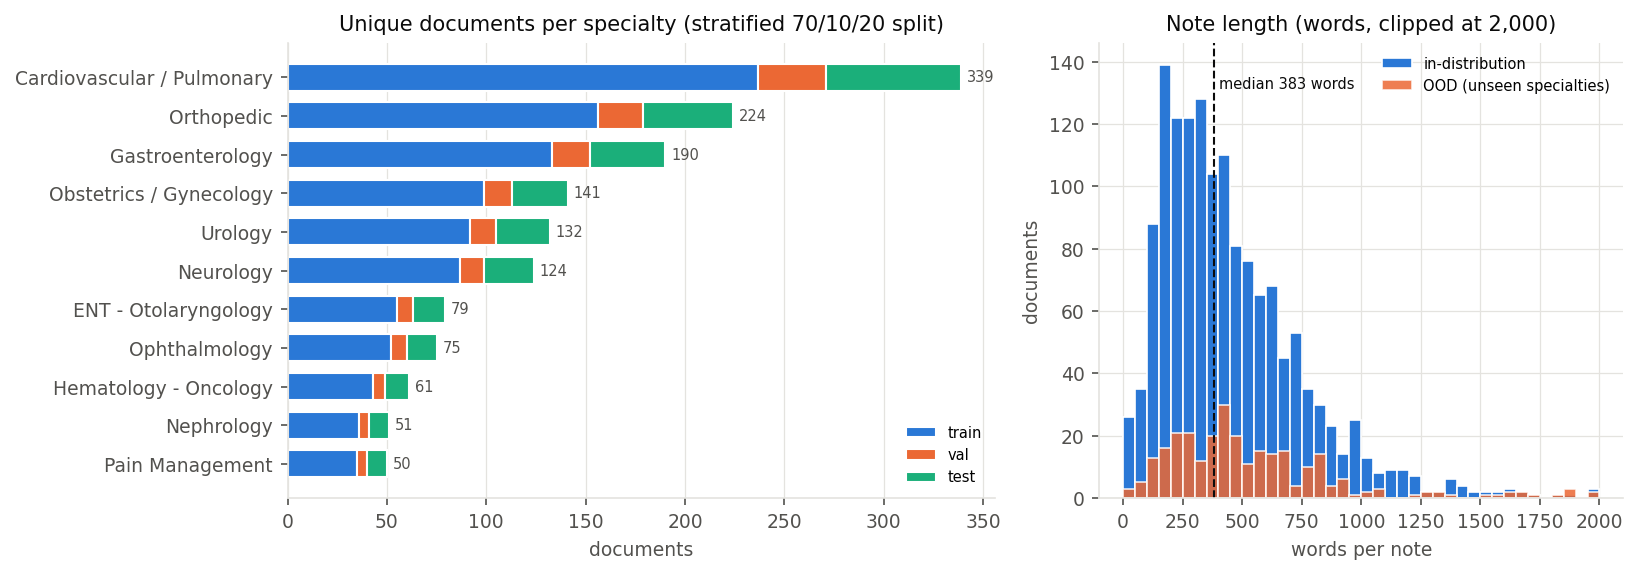

In [2]:
s = load_splits()
rebuilt = build_dataset(save=False)
for name in ("train", "val", "test", "ood"):
    pd.testing.assert_frame_equal(getattr(s, name), getattr(rebuilt, name))
print(json.dumps(s.stats, indent=2))
import itertools
overlaps = {f"{a}/{b}": len(set(getattr(s, a).text) & set(getattr(s, b).text))
            for a, b in itertools.combinations(("train", "val", "test", "ood"), 2)}
assert not any(overlaps.values())
print("Exact normalized text overlaps:", overlaps)
display(Image(filename=str(F / "data_overview.png")))

**Observations**

- Duplicate grouping reduced 4,966 nonmissing rows to 2,357 unique transcriptions, removing 2,609 rows. The classification set contains 1,466 documents across 11 specialties after label filtering.
- Another 279 notes belong to 19 unseen specialties. The 317 documents with multiple retained specialty labels were excluded, leaving their classification difficulty outside the scores.

## Step 2. Preprocessing

Preprocessing consists of five operations:

1. **Identifier screening:** regular expressions replace email addresses, phone numbers, dates, selected identifiers, and titled names. Across the 1,745 retained documents, including unseen specialties, the script replaced 880 date strings, 334 titled names, and one phone number. These counts record pattern matches. Complete PHI removal was not verified, and the script alone does not meet a formal de-identification standard.
2. **Normalization:** punctuation artifacts and repeated whitespace are cleaned. A dictionary of 34 abbreviations produces 692 expansions. DM, CVA, and LOC can have different meanings depending on context; clinicians have not reviewed the expansions for accuracy.
3. **Feature extraction:** TF-IDF is fitted within each grid-search training fold, using sublinear term frequency, minimum document frequency 2, maximum document frequency 90%, and unigram or bigram candidates. The token pattern retains tokens of at least two characters beginning with a letter and permits subsequent letters, digits, or hyphens. Transformer models use their checkpoint-specific vocabularies.
4. **Imbalance handling:** Logistic Regression and SVM use balanced class weights; Random Forest uses `balanced_subsample`; transformers use class-weighted cross-entropy. The largest retained class contains 339 documents and the smallest 50, a ratio of 6.78:1. Macro-F1 gives each specialty equal weight.
5. **Splitting:** stratified splitting with seed 42 assigns approximately 70% of notes to training, 10% to validation, and 20% to testing: 1,025, 147, and 294 documents. Rebuilding the splits reproduced every row in its saved order. No exact normalized text appears in more than one split, including the unseen-specialty set. Near duplicates and shared patient histories remain possible.

The tokenizer audit measures the training notes only:


| model | vocab_size | fertility (pieces/word) | clinical terms kept whole (/30) | median tokens/note | % notes > 256 tokens |
|---|---|---|---|---|---|
| clinicalbert | 28996 | 1.45 | 1 | 672.00 | 88.98 |
| pubmedbert | 30522 | 1.12 | 23 | 534.00 | 82.24 |
| biobert | 28996 | 1.45 | 1 | 672.00 | 88.98 |
| roberta | 50265 | 1.29 | 4 | 601.00 | 86.15 |



*Table 1. Vocabulary size, token fragmentation, a 30-term vocabulary check, and the share of training notes exceeding the input limit. Fragmentation alone cannot explain performance differences.*

Case is preserved for BioBERT and Bio_ClinicalBERT. In the saved masked-language-model check on 24 notes, preserved case gave lower loss: 1.348 versus 1.655 for BioBERT, and 1.371 versus 1.655 for Bio_ClinicalBERT. Different tokenizations can change the prediction targets themselves, so this small check offers limited support for the choice. It does not establish which setting would classify notes better.

The `sex` field comes from gendered words in raw notes, requiring at least two cues and a 2:1 majority. Age comes from the first matching year-old expression. A cue could describe a spouse or another person. Neither field has been checked against patient records, and the sex field cannot establish biological sex or gender identity.

![Figure 2. Retained specialty counts and document lengths. The main corpus has a median length of 383 words.](../results/figures/data_overview.png)

In [3]:
display(pd.read_csv(T / "tokenizer_stats.csv"))
print("Saved masked-language-model casing check:")
print((ROOT / "results/mlm_casing_check.json").read_text(encoding="utf-8"))
print("Test demographic proxies (unknown values are retained):")
display(pd.crosstab(s.test.sex, s.test.age_group, margins=True))

,model,checkpoint,vocab_size,lowercase input,layers,hidden,heads,fertility (pieces/word),% words split,clinical terms kept whole (/30),median tokens/note,% notes > 256 tokens
0,clinicalbert,emilyalsentzer/Bio_ClinicalBERT,28996,False,12,768,12,1.4503,20.508,1,672.0,88.9756
1,pubmedbert,microsoft/BiomedNLP-BiomedBERT-base-uncased-ab...,30522,True,12,768,12,1.1171,8.114,23,534.0,82.2439
2,biobert,dmis-lab/biobert-base-cased-v1.2,28996,False,12,768,12,1.4503,20.508,1,672.0,88.9756
3,roberta,FacebookAI/roberta-base,50265,False,12,768,12,1.2888,17.288,4,601.0,86.1463


Saved masked-language-model casing check:
{
  "dmis-lab/biobert-base-cased-v1.2 lowercase=True": 1.6546569855806108,
  "dmis-lab/biobert-base-cased-v1.2 lowercase=False": 1.3480646287401516,
  "emilyalsentzer/Bio_ClinicalBERT lowercase=True": 1.6548239224745582,
  "emilyalsentzer/Bio_ClinicalBERT lowercase=False": 1.370990698536237
}
Test demographic proxies (unknown values are retained):


age_group,18-64,65+,<18,unknown,All
sex,,,,,
female,36,17,4,32,89
male,30,23,9,29,91
unknown,8,4,1,101,114
All,74,44,14,162,294


**Observations**

- Screening replaced 880 date strings, 334 titled names, and one phone number; abbreviation expansion produced 692 replacements. These counts describe matches rather than privacy protection.
- The splits contain 1,025 training, 147 validation, and 294 test notes. Normalized text overlap between splits is zero; the largest class outnumbers the smallest 6.78:1.

## Step 3. Model selection

Three traditional classifiers and four transformers use the same splits and label mapping. Each transformer has 12 encoder layers, a hidden size of 768, and 12 attention heads.

| Model | Architecture and features | Training in this study | Input scope |
|---|---|---|---|
| Logistic Regression | Multinomial linear classifier over TF-IDF | All classifier weights; selected unigram vocabulary | Full note |
| Linear SVM | Linear maximum-margin classifier with sigmoid calibration | Five classifier/calibrator pairs; selected unigrams | Full note |
| Random Forest | Ensemble of decision trees over up to 20,000 TF-IDF features | 300 selected trees; unigram and bigram features | Full note |
| BioBERT v1.2 | Biomedical BERT with cased WordPiece vocabulary | Top two layers and classification head; approximately 14.2 million parameters | First 256 tokens |
| Bio_ClinicalBERT | Clinical BERT adapted from BioBERT | Top two layers and head; approximately 14.2 million parameters | First 256 tokens |
| PubMedBERT / BiomedBERT | Biomedical BERT with in-domain uncased vocabulary | Top two layers and head; approximately 14.2 million parameters | First 256 tokens |
| RoBERTa-base | General-domain encoder with byte-level BPE | Top two layers and head; approximately 14.2 million parameters | First 256 tokens |

*Table 2. Architecture comparison. The 256-token limit includes special tokens; RoBERTa uses BPE rather than WordPiece.*

The exact checkpoints are `dmis-lab/biobert-base-cased-v1.2`, `emilyalsentzer/Bio_ClinicalBERT`, `microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext`, and `FacebookAI/roberta-base`. Microsoft's [model card](https://huggingface.co/microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext) documents the PubMedBERT-to-BiomedBERT naming change and this abstract-plus-full-text checkpoint.

Input length differs between systems. TF-IDF sees the whole note; transformers see a prefix. To examine that difference, an additional Logistic Regression model receives the prefix covered by Bio_ClinicalBERT's first 256 tokens. PubMedBERT and RoBERTa tokenize differently, so their prefixes do not match this control exactly. Throughout the report, ClinicalBERT refers specifically to Bio_ClinicalBERT.

In [4]:
display(pd.read_csv(T / "architectures.csv"))

,Model,Architecture,Pre-training,Features / vocabulary,Size,Trainable in this study,Input
0,TF-IDF + Logistic Regression,Linear (multinomial),none (trained from scratch),"TF-IDF unigrams, learned on train","99,242 weights",all,full note
1,TF-IDF + Linear SVM,Linear max-margin + Platt calibration,none,"TF-IDF unigrams, learned on train","496,210 weights",all,full note
2,TF-IDF + Random Forest,Bagged decision trees,none,"TF-IDF uni+bigrams, top 20k","300 trees, 108,286 nodes",all,full note
3,BioBERT v1.2,"BERT-base encoder (cased), 12 layers, 768-d, 1...",BERT init. + PubMed abstracts,"WordPiece, 28,996 (general BERT vocab)",108.3 M parameters,top 2 layers + head (14.2 M),first 256 word-pieces
4,Bio_ClinicalBERT,"BERT-base encoder (cased), 12 layers, 768-d, 1...",BioBERT init. + MIMIC-III clinical notes,"WordPiece, 28,996 (general BERT vocab)",108.3 M parameters,top 2 layers + head (14.2 M),first 256 word-pieces
5,PubMedBERT (BiomedBERT),"BERT-base encoder (uncased), 12 layers, 768-d,...",from scratch: PubMed abstracts + PMC full text,"WordPiece, 30,522 (in-domain vocab)",109.5 M parameters,top 2 layers + head (14.2 M),first 256 word-pieces
6,RoBERTa-base,"RoBERTa-base encoder, 12 layers, 768-d, 12 heads","general domain (books, Wikipedia, news, web)","byte-level BPE, 50,265",124.7 M parameters,top 2 layers + head (14.2 M),first 256 word-pieces


**Observations**

- The table contains three TF-IDF classifiers and four transformers. Each transformer trains approximately 14.2 million parameters, while its frozen layers remain part of inference cost.
- PubMedBERT represents 23 of 30 terms as single tokens, compared with one for BioBERT. Median training-note lengths are 534 and 672 tokens, exceeding input limits.

## Step 4. Training

The classical models are tuned with five stratified folds from the 1,025 training documents. Each fold refits the complete TF-IDF pipeline. Mean macro-F1 determines the selected settings.

| Model | Search space | Selected configuration | Training CV macro-F1 |
|---|---|---|---:|
| Logistic Regression | C = 1, 10, 100, 1000; unigrams or unigrams plus bigrams | C = 100; unigrams | 0.8888 |
| Linear SVM | C = 0.1, 0.5, 1, 5; same n-gram options | C = 0.5; unigrams | 0.8956 |
| Random Forest | 300 or 600 trees; max_features = sqrt or 0.05; minimum leaf size = 1 or 2 | 300 trees; sqrt; minimum leaf size 2 | 0.8199 |

*Table 3. Search results from `results/classical_training.json`. The SVM CV score evaluates the uncalibrated classifier; final SVM probabilities come from a subsequent calibration ensemble.*

SVM probabilities come from sigmoid calibration with five internal folds. Here, TF-IDF is fitted on the entire training split before calibration, allowing the calibration folds to share vocabulary and inverse document frequencies. Validation and test notes remain outside that fitting. A stricter implementation would place the whole text pipeline inside the calibration wrapper and tune it there.

Training used an Intel Core i3-N305 CPU with eight threads and no GPU. To reduce the cost, the transformers cache lower-layer states in float16, then train the top two layers and a classification head consisting of masked mean pooling, dropout, and a linear layer. The frozen layers run in evaluation mode, with their dropout disabled. Cached float16 states introduce rounding; this setup differs from running the whole network in training mode.

The common transformer settings are maximum length 256 tokens, batch size 16, AdamW, weight decay 0.01, 10% warm-up followed by linear decay, class-weighted cross-entropy, and gradient norm clipping at 1.0. The learning-rate grid is {0.00003, 0.0001}. Validation macro-F1 controls early stopping with patience two, at most six epochs, and restoration of the best checkpoint. Classical models use their own optimization algorithms; gradient clipping and neural-network early stopping do not apply to those estimators.

| Transformer | Selected learning rate | Selected epoch | Validation macro-F1 |
|---|---:|---:|---:|
| BioBERT | 0.0001 | 5 | 0.8863 |
| Bio_ClinicalBERT | 0.00003 | 5 | 0.9096 |
| PubMedBERT | 0.0001 | 6 | 0.9358 |
| RoBERTa | 0.0001 | 4 | 0.8533 |

*Table 4. Selected checkpoints from the saved training histories; seed 42.*

Freezing layers follows an approach studied by Lee et al. (2019). It saves computation, but the effect on this dataset is unknown: full fine-tuning could improve or worsen the scores. The experiment uses one seed and two learning rates, leaving much of that uncertainty unmeasured.

MLflow contains 399 metric entries and 19 run records. Eighteen are marked FINISHED; one is still marked RUNNING. Its status needs to be checked against the logs. The selected models have saved training histories, but those records do not explain why the other run was left open.

Five-by-two and ten-fold resampling use the combined training and validation notes. They cover the classical methods and frozen transformer embeddings fitted with Logistic Regression probes. The fine-tuned transformers were not retrained in each fold, leaving that part of the assignment incomplete.

![Figure 3. Saved training loss and validation macro-F1 histories for both learning-rate settings.](../results/figures/training_curves.png)

,best_params,cv_macro_f1,val_macro_f1
logreg,"{'clf__C': '100', 'tfidf__ngram_range': '(1, 1)'}",0.8888,0.9304
svm,"{'clf__C': '0.5', 'tfidf__ngram_range': '(1, 1)'}",0.8956,0.9333
rf,"{'clf__max_features': 'sqrt', 'clf__min_sample...",0.8199,0.8725
logreg_trunc256,"{'clf__C': '100', 'tfidf__ngram_range': '(1, 1)'}",0.8566,NaN


,model,lr,best_epoch,epochs_run,validation_macro_f1,selected
0,biobert,3.0000e-05,5,6,0.8660,False
1,biobert,1.0000e-04,5,6,0.8863,True
2,clinicalbert,3.0000e-05,5,6,0.9096,True
3,clinicalbert,1.0000e-04,4,6,0.8815,False
4,pubmedbert,3.0000e-05,3,5,0.9009,False
5,pubmedbert,1.0000e-04,6,6,0.9358,True
6,roberta,3.0000e-05,6,6,0.8100,False
7,roberta,1.0000e-04,4,6,0.8533,True


MLflow status counts: [('FINISHED', 18), ('RUNNING', 1)]
MLflow metric records: 399


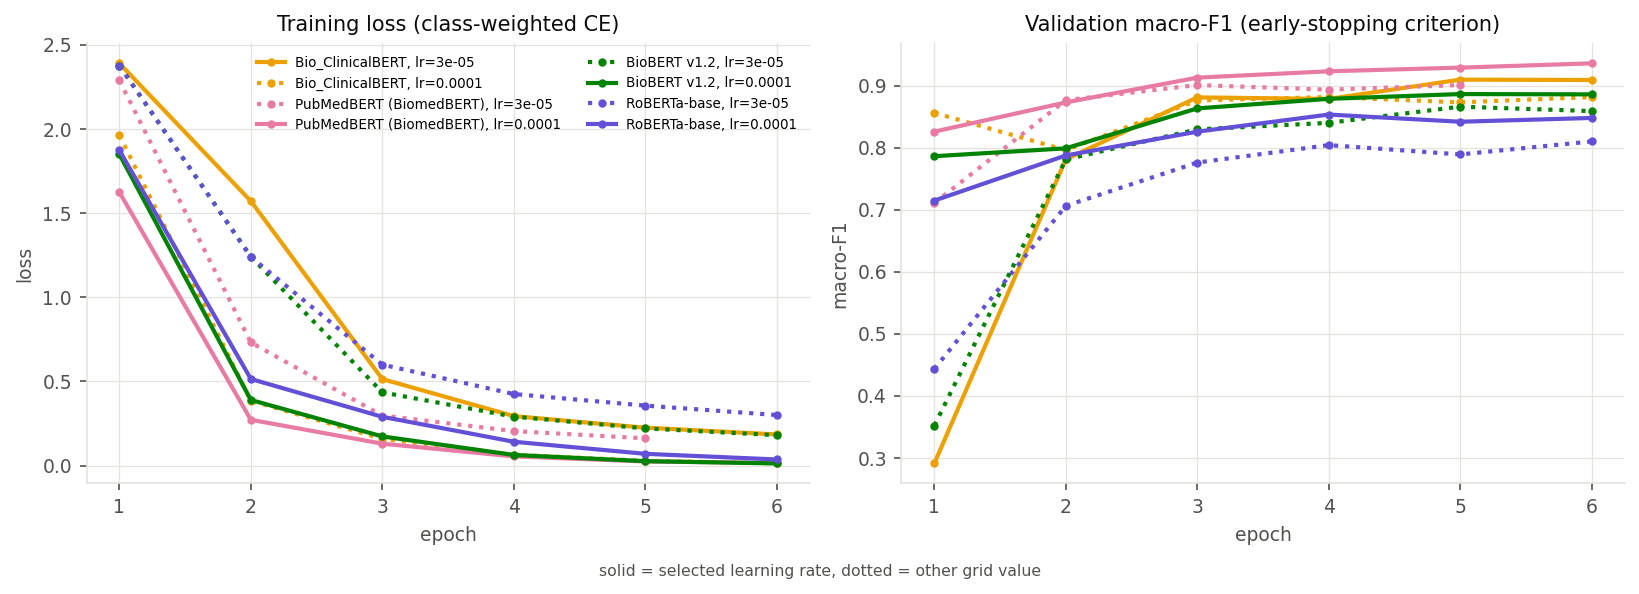

In [5]:
training = json.loads((ROOT / "results/classical_training.json").read_text())
display(pd.DataFrame(training).T[["best_params", "cv_macro_f1", "val_macro_f1"]])
rows = []
for model in ("biobert", "clinicalbert", "pubmedbert", "roberta"):
    info = json.loads((ROOT / f"results/transformer_{model}.json").read_text())
    for run in info["grid"]:
        rows.append({"model": model, "lr": run["lr"], "best_epoch": run["best_epoch"],
                     "epochs_run": len(run["history"]), "validation_macro_f1": run["best_val_macro_f1"],
                     "selected": run["lr"] == info["best_lr"]})
display(pd.DataFrame(rows))
db = sqlite3.connect(f"file:{(ROOT / 'mlflow.db').as_posix()}?mode=ro", uri=True)
print("MLflow status counts:", db.execute("SELECT status, COUNT(*) FROM runs GROUP BY status").fetchall())
print("MLflow metric records:", db.execute("SELECT COUNT(*) FROM metrics").fetchone()[0])
db.close()
display(Image(filename=str(F / "training_curves.png")))

**Observations**

- PubMedBERT's checkpoint occurs at epoch six with validation macro-F1 0.9358. Bio_ClinicalBERT reaches 0.9096 at epoch five; BioBERT and RoBERTa reach 0.8863 and 0.8533, respectively.
- Grid-search macro-F1 is 0.8956 for SVM, 0.8888 for Logistic Regression, and 0.8199 for Random Forest. These cross-validation scores describe different samples from the transformer validation scores.

## Step 5. Evaluation: predictive performance, robustness, and fairness

### Predictive performance

The test set contains 294 notes across 11 specialties. Accuracy counts correct labels; macro precision, recall, and F1 give each specialty equal weight. Weighted F1 accounts for class size. ROC-AUC is calculated one-versus-rest with macro and micro averages. Expected calibration error (ECE) uses 15 equal-width confidence bins to compare stated confidence with observed correctness (Guo et al., 2017).


| Model | Accuracy | Macro-P | Macro-R | Macro-F1 | Weighted-F1 | ROC-AUC (macro OvR) | ECE |
|---|---|---|---|---|---|---|---|
| TF-IDF + Logistic Regression | 0.9388 | 0.9405 | 0.9217 | 0.9280 | 0.9378 | 0.9964 | 0.1166 |
| TF-IDF + Linear SVM | 0.9388 | 0.9373 | 0.9131 | 0.9221 | 0.9383 | 0.9961 | 0.1502 |
| TF-IDF + Random Forest | 0.8605 | 0.8879 | 0.8350 | 0.8484 | 0.8558 | 0.9869 | 0.3779 |
| Bio_ClinicalBERT | 0.9048 | 0.8796 | 0.9149 | 0.8936 | 0.9064 | 0.9898 | 0.0325 |
| PubMedBERT (BiomedBERT) | 0.9422 | 0.9269 | 0.9457 | 0.9347 | 0.9431 | 0.9915 | 0.0354 |
| BioBERT v1.2 | 0.9184 | 0.8914 | 0.9161 | 0.9016 | 0.9192 | 0.9928 | 0.0549 |
| RoBERTa-base | 0.8946 | 0.8750 | 0.8889 | 0.8799 | 0.8960 | 0.9892 | 0.0587 |
| TF-IDF + LR (first 256 tokens) | 0.8912 | 0.9066 | 0.8683 | 0.8811 | 0.8922 | 0.9934 | 0.0874 |



*Table 5. Test metrics, as proportions. The eighth row is a length ablation rather than an additional architecture.*


| Model | Acc 95% CI | F1 95% CI |
|---|---|---|
| TF-IDF + Logistic Regression | [0.912, 0.963] | [0.887, 0.958] |
| TF-IDF + Linear SVM | [0.912, 0.963] | [0.877, 0.954] |
| TF-IDF + Random Forest | [0.820, 0.898] | [0.795, 0.891] |
| Bio_ClinicalBERT | [0.871, 0.935] | [0.849, 0.928] |
| PubMedBERT (BiomedBERT) | [0.912, 0.966] | [0.898, 0.963] |
| BioBERT v1.2 | [0.888, 0.946] | [0.855, 0.936] |
| RoBERTa-base | [0.857, 0.929] | [0.830, 0.921] |
| TF-IDF + LR (first 256 tokens) | [0.854, 0.929] | [0.828, 0.921] |



*Table 6. Percentile 95% bootstrap intervals from 1,000 resamples of test notes. The fitted models stay fixed, so the intervals exclude variation from retraining or model selection.*

PubMedBERT gets 277 labels right. Logistic Regression and SVM each get 276. Rankings change with the metric: Logistic Regression has the higher macro ROC-AUC, 0.9964 versus 0.9915, and Bio_ClinicalBERT has the lowest ECE at 0.0325. Calibration on these notes still leaves open how confidence behaves on unfamiliar inputs.

Restricting Logistic Regression to the 256-token prefix lowers macro-F1 from 0.9280 to 0.8811, a drop of 0.0469. Later parts of a note appear useful to this model. Because the transformer tokenizers produce different prefixes, the ablation cannot isolate architecture effects across all four encoders.

![Figure 4. Row-normalized confusion matrices for all seven architectures; rows are true specialties and columns predicted specialties.](../results/figures/confusion_matrices.png)

![Figure 5. Micro-averaged ROC curves and class-specific ROC curves for the validation-selected PubMedBERT model.](../results/figures/roc_curves.png)

![Figure 6. Reliability plots. The plot uses ten bins and displays bins containing at least five notes; the tabulated ECE uses fifteen bins.](../results/figures/reliability.png)

### Robustness and unseen-specialty detection

The robustness tests introduce typos with probabilities 0.10 and 0.25, delete words with probability 0.20, or mask specialty terms. The masking list contains 164 distinct terms drawn from the top 15 Logistic Regression unigram coefficients for each class. This targets the linear model and tests transfer to the others. Actual corruption rates vary by note. No optimized adversarial search was run, and clinicians did not verify that the altered notes retained their original meaning.


| Model | clean | typo_10 | typo_25 | word_drop_20 | keyword_mask | OOD AUROC (MSP) | OOD FPR@95TPR |
|---|---|---|---|---|---|---|---|
| TF-IDF + Logistic Regression | 0.9280 | 0.9327 | 0.9093 | 0.9071 | 0.8346 | 0.9139 | 0.4588 |
| TF-IDF + Linear SVM | 0.9221 | 0.9268 | 0.9106 | 0.9037 | 0.8146 | 0.9009 | 0.5233 |
| TF-IDF + Random Forest | 0.8484 | 0.8590 | 0.8517 | 0.8600 | 0.5945 | 0.8702 | 0.6201 |
| Bio_ClinicalBERT | 0.8936 | 0.8944 | 0.8770 | 0.8765 | 0.7452 | 0.8134 | 0.7742 |
| PubMedBERT (BiomedBERT) | 0.9347 | 0.9414 | 0.9314 | 0.9157 | 0.8615 | 0.8414 | 0.6595 |
| BioBERT v1.2 | 0.9016 | 0.9040 | 0.8975 | 0.8886 | 0.7696 | 0.8296 | 0.7742 |
| RoBERTa-base | 0.8799 | 0.8940 | 0.8789 | 0.8947 | 0.7121 | 0.8107 | 0.7384 |



*Table 7. Perturbation macro-F1 and maximum-probability OOD detection. Higher AUROC is better; lower OOD false-positive rate is better.*

Masking keywords lowers PubMedBERT's macro-F1 from 0.9347 to 0.8615 and Logistic Regression's from 0.9280 to 0.8346. Some mild corruptions improve scores slightly on this test set. Each condition has only one generated version, so those small changes could depend on which words were altered. Removing clinical terms can also remove valid evidence for a label.

Unseen-specialty detection uses the largest predicted class probability, following Hendrycks and Gimpel (2017). SVM contributes calibrated probabilities; Random Forest uses its native estimates. In-distribution notes count as positive. A threshold at the fifth percentile of their test confidence retains roughly 95% of them. OOD FPR reports how many unseen-specialty notes also pass that threshold. This test-set calculation describes model behavior; any threshold used in practice would need separate validation data.

Logistic Regression separates known from unseen specialties better, with OOD AUROC 0.9139 against PubMedBERT's 0.8414. Even so, it accepts 45.88% of unseen-specialty notes at this threshold. PubMedBERT accepts 65.95% and assigns those OOD notes a mean maximum probability of 0.8455. Both models can give confident answers when the correct specialty is absent from their label set.

![Figure 7. Macro-F1 under each perturbation condition.](../results/figures/robustness.png)

### Exploratory fairness assessment

Demographic parity difference compares predicted label frequencies between groups A and B, taking the largest absolute class-specific gap. Equal opportunity compares per-class true-positive rates, following Hardt et al. (2016). A class enters that calculation only if both groups have at least five notes. The group labels come from text cues rather than verified demographics.


| Model | attribute | group A | acc A | group B | acc B | DP diff (max over classes) | EO gap max \|dTPR\| | EO classes evaluated |
|---|---|---|---|---|---|---|---|---|
| TF-IDF + Logistic Regression | sex | female (n=89) | 0.9438 | male (n=91) | 0.9341 | 0.1913 | 0.1538 | 4 |
| TF-IDF + Linear SVM | sex | female (n=89) | 0.9326 | male (n=91) | 0.9341 | 0.1800 | 0.1538 | 4 |
| TF-IDF + Random Forest | sex | female (n=89) | 0.8539 | male (n=91) | 0.8462 | 0.1913 | 0.1329 | 4 |
| Bio_ClinicalBERT | sex | female (n=89) | 0.8876 | male (n=91) | 0.8571 | 0.1803 | 0.1667 | 4 |
| PubMedBERT (BiomedBERT) | sex | female (n=89) | 0.9101 | male (n=91) | 0.9341 | 0.1913 | 0.1667 | 4 |
| BioBERT v1.2 | sex | female (n=89) | 0.9101 | male (n=91) | 0.8791 | 0.2250 | 0.1399 | 4 |
| RoBERTa-base | sex | female (n=89) | 0.8764 | male (n=91) | 0.8681 | 0.2137 | 0.1278 | 4 |
| TF-IDF + Logistic Regression | age_group | 18-64 (n=74) | 0.8784 | 65+ (n=44) | 0.9545 | 0.1622 | 0.2143 | 3 |
| TF-IDF + Linear SVM | age_group | 18-64 (n=74) | 0.8784 | 65+ (n=44) | 0.9545 | 0.1622 | 0.2143 | 3 |
| TF-IDF + Random Forest | age_group | 18-64 (n=74) | 0.8378 | 65+ (n=44) | 0.7500 | 0.1622 | 0.2302 | 3 |
| Bio_ClinicalBERT | age_group | 18-64 (n=74) | 0.8649 | 65+ (n=44) | 0.8864 | 0.1622 | 0.2857 | 3 |
| PubMedBERT (BiomedBERT) | age_group | 18-64 (n=74) | 0.9054 | 65+ (n=44) | 0.9318 | 0.1824 | 0.1000 | 3 |
| BioBERT v1.2 | age_group | 18-64 (n=74) | 0.8649 | 65+ (n=44) | 0.8864 | 0.1892 | 0.1190 | 3 |
| RoBERTa-base | age_group | 18-64 (n=74) | 0.9054 | 65+ (n=44) | 0.8636 | 0.1757 | 0.2222 | 3 |



*Table 8. Proxy subgroup comparisons. DP denotes demographic parity; EO denotes equal opportunity. EO coverage is only four classes for the sex proxy and three for the adult-age comparison.*

Text cues classify 89 test notes as female-coded and 91 as male-coded; 114 remain unknown. Age extraction identifies 74 notes aged 18–64, 44 aged 65 or older, and 14 younger than 18, leaving 162 unknown. The adult comparison excludes the younger group. Missing values and small class-by-group samples leave much of the population unexamined.

PubMedBERT accuracy is 91.01% on female-coded notes and 93.41% on male-coded notes. Its maximum EO gaps are 0.1667 for sex proxies and 0.1000 for adult age. The sex-proxy DP difference, 0.1913, equals the largest gap in true label frequencies. Matching those two maxima says nothing about whether every class has matching disparities. Specialties linked to sex or age also have different base rates, which complicates interpretation.


| Model | flips (n) | flip rate (all) | macro-F1 swapped |
|---|---|---|---|
| TF-IDF + Logistic Regression | 9 | 0.0306 | 0.9256 |
| TF-IDF + Linear SVM | 2 | 0.0068 | 0.9304 |
| TF-IDF + Random Forest | 4 | 0.0136 | 0.8478 |
| Bio_ClinicalBERT | 2 | 0.0068 | 0.8920 |
| PubMedBERT (BiomedBERT) | 1 | 0.0034 | 0.9348 |
| BioBERT v1.2 | 1 | 0.0034 | 0.9015 |
| RoBERTa-base | 10 | 0.0340 | 0.8699 |



*Table 9. Sensitivity to automated gendered-word substitutions, evaluated on all 294 test notes.*

Swapping gendered words changes one PubMedBERT prediction, nine Logistic Regression predictions, and ten RoBERTa predictions. A swap can produce medically inconsistent text, so this measures sensitivity to substitutions rather than causal counterfactual fairness. Small flip rates and nonsignificant subgroup tests leave discrimination unresolved. Race, ethnicity, language, socioeconomic status, and intersections between groups were not assessed.

             model                           Model  Accuracy      Acc 95% CI  Macro-P  Macro-R  Macro-F1       F1 95% CI  Weighted-F1  ROC-AUC (macro OvR)  ROC-AUC (micro)     ECE
0           logreg    TF-IDF + Logistic Regression    0.9388  [0.912, 0.963]   0.9405   0.9217    0.9280  [0.887, 0.958]       0.9378               0.9964           0.9972  0.1166
1              svm             TF-IDF + Linear SVM    0.9388  [0.912, 0.963]   0.9373   0.9131    0.9221  [0.877, 0.954]       0.9383               0.9961           0.9968  0.1502
2               rf          TF-IDF + Random Forest    0.8605  [0.820, 0.898]   0.8879   0.8350    0.8484  [0.795, 0.891]       0.8558               0.9869           0.9898  0.3779
3     clinicalbert                Bio_ClinicalBERT    0.9048  [0.871, 0.935]   0.8796   0.9149    0.8936  [0.849, 0.928]       0.9064               0.9898           0.9885  0.0325
4       pubmedbert         PubMedBERT (BiomedBERT)    0.9422  [0.912, 0.966]   0.9269   0.9457    0.

,model,Model,Accuracy,Acc 95% CI,Macro-P,Macro-R,Macro-F1,F1 95% CI,Weighted-F1,ROC-AUC (macro OvR),ROC-AUC (micro),ECE
0,logreg,TF-IDF + Logistic Regression,0.9388,"[0.912, 0.963]",0.9405,0.9217,0.9280,"[0.887, 0.958]",0.9378,0.9964,0.9972,0.1166
1,svm,TF-IDF + Linear SVM,0.9388,"[0.912, 0.963]",0.9373,0.9131,0.9221,"[0.877, 0.954]",0.9383,0.9961,0.9968,0.1502
2,rf,TF-IDF + Random Forest,0.8605,"[0.820, 0.898]",0.8879,0.8350,0.8484,"[0.795, 0.891]",0.8558,0.9869,0.9898,0.3779
3,clinicalbert,Bio_ClinicalBERT,0.9048,"[0.871, 0.935]",0.8796,0.9149,0.8936,"[0.849, 0.928]",0.9064,0.9898,0.9885,0.0325
4,pubmedbert,PubMedBERT (BiomedBERT),0.9422,"[0.912, 0.966]",0.9269,0.9457,0.9347,"[0.898, 0.963]",0.9431,0.9915,0.9947,0.0354
5,biobert,BioBERT v1.2,0.9184,"[0.888, 0.946]",0.8914,0.9161,0.9016,"[0.855, 0.936]",0.9192,0.9928,0.9898,0.0549
6,roberta,RoBERTa-base,0.8946,"[0.857, 0.929]",0.8750,0.8889,0.8799,"[0.830, 0.921]",0.8960,0.9892,0.9916,0.0587
7,logreg_trunc256,TF-IDF + LR (first 256 tokens),0.8912,"[0.854, 0.929]",0.9066,0.8683,0.8811,"[0.828, 0.921]",0.8922,0.9934,0.9934,0.0874


,model,Model,clean,typo_10,typo_25,word_drop_20,keyword_mask,OOD AUROC (MSP),OOD FPR@95TPR,mean MSP in-dist,mean MSP OOD
0,logreg,TF-IDF + Logistic Regression,0.9280,0.9327,0.9093,0.9071,0.8346,0.9139,0.4588,0.8253,0.4055
1,svm,TF-IDF + Linear SVM,0.9221,0.9268,0.9106,0.9037,0.8146,0.9009,0.5233,0.7895,0.4600
2,rf,TF-IDF + Random Forest,0.8484,0.8590,0.8517,0.8600,0.5945,0.8702,0.6201,0.4827,0.2432
3,clinicalbert,Bio_ClinicalBERT,0.8936,0.8944,0.8770,0.8765,0.7452,0.8134,0.7742,0.8993,0.6971
4,pubmedbert,PubMedBERT (BiomedBERT),0.9347,0.9414,0.9314,0.9157,0.8615,0.8414,0.6595,0.9742,0.8455
5,biobert,BioBERT v1.2,0.9016,0.9040,0.8975,0.8886,0.7696,0.8296,0.7742,0.9619,0.8088
6,roberta,RoBERTa-base,0.8799,0.8940,0.8789,0.8947,0.7121,0.8107,0.7384,0.9449,0.7967


,attribute,model,Model,group A,acc A,group B,acc B,acc unknown,acc gap (A-B),acc gap p (Fisher),DP diff (max over classes),"DP diff, ground truth",EO gap mean |dTPR|,EO gap max |dTPR|,EO classes evaluated
0,sex,logreg,TF-IDF + Logistic Regression,female (n=89),0.9438,male (n=91),0.9341,0.9386,0.0098,1.0000,0.1913,0.1913,0.0811,0.1538,4
1,sex,svm,TF-IDF + Linear SVM,female (n=89),0.9326,male (n=91),0.9341,0.9474,-0.0015,1.0000,0.1800,0.1913,0.0619,0.1538,4
2,sex,rf,TF-IDF + Random Forest,female (n=89),0.8539,male (n=91),0.8462,0.8772,0.0078,1.0000,0.1913,0.1913,0.0770,0.1329,4
3,sex,clinicalbert,Bio_ClinicalBERT,female (n=89),0.8876,male (n=91),0.8571,0.9561,0.0305,0.6565,0.1803,0.1913,0.1095,0.1667,4
4,sex,pubmedbert,PubMedBERT (BiomedBERT),female (n=89),0.9101,male (n=91),0.9341,0.9737,-0.0240,0.5891,0.1913,0.1913,0.1154,0.1667,4
5,sex,biobert,BioBERT v1.2,female (n=89),0.9101,male (n=91),0.8791,0.9561,0.0310,0.6291,0.2250,0.1913,0.0737,0.1399,4
6,sex,roberta,RoBERTa-base,female (n=89),0.8764,male (n=91),0.8681,0.9298,0.0083,1.0000,0.2137,0.1913,0.0807,0.1278,4
7,age_group,logreg,TF-IDF + Logistic Regression,18-64 (n=74),0.8784,65+ (n=44),0.9545,0.9568,-0.0762,0.2070,0.1622,0.1505,0.0825,0.2143,3
8,age_group,svm,TF-IDF + Linear SVM,18-64 (n=74),0.8784,65+ (n=44),0.9545,0.9568,-0.0762,0.2070,0.1622,0.1505,0.0825,0.2143,3
9,age_group,rf,TF-IDF + Random Forest,18-64 (n=74),0.8378,65+ (n=44),0.7500,0.8889,0.0878,0.3365,0.1622,0.1505,0.1156,0.2302,3


,model,Model,flip rate (all),flips (n),flip rate (docs with sex cues),mean |dP(true class)|,macro-F1 swapped
0,logreg,TF-IDF + Logistic Regression,0.0306,9,0.0444,0.0201,0.9256
1,svm,TF-IDF + Linear SVM,0.0068,2,0.0056,0.0122,0.9304
2,rf,TF-IDF + Random Forest,0.0136,4,0.0222,0.0065,0.8478
3,clinicalbert,Bio_ClinicalBERT,0.0068,2,0.0111,0.0068,0.8920
4,pubmedbert,PubMedBERT (BiomedBERT),0.0034,1,0.0056,0.0019,0.9348
5,biobert,BioBERT v1.2,0.0034,1,0.0056,0.0033,0.9015
6,roberta,RoBERTa-base,0.0340,10,0.0500,0.0300,0.8699


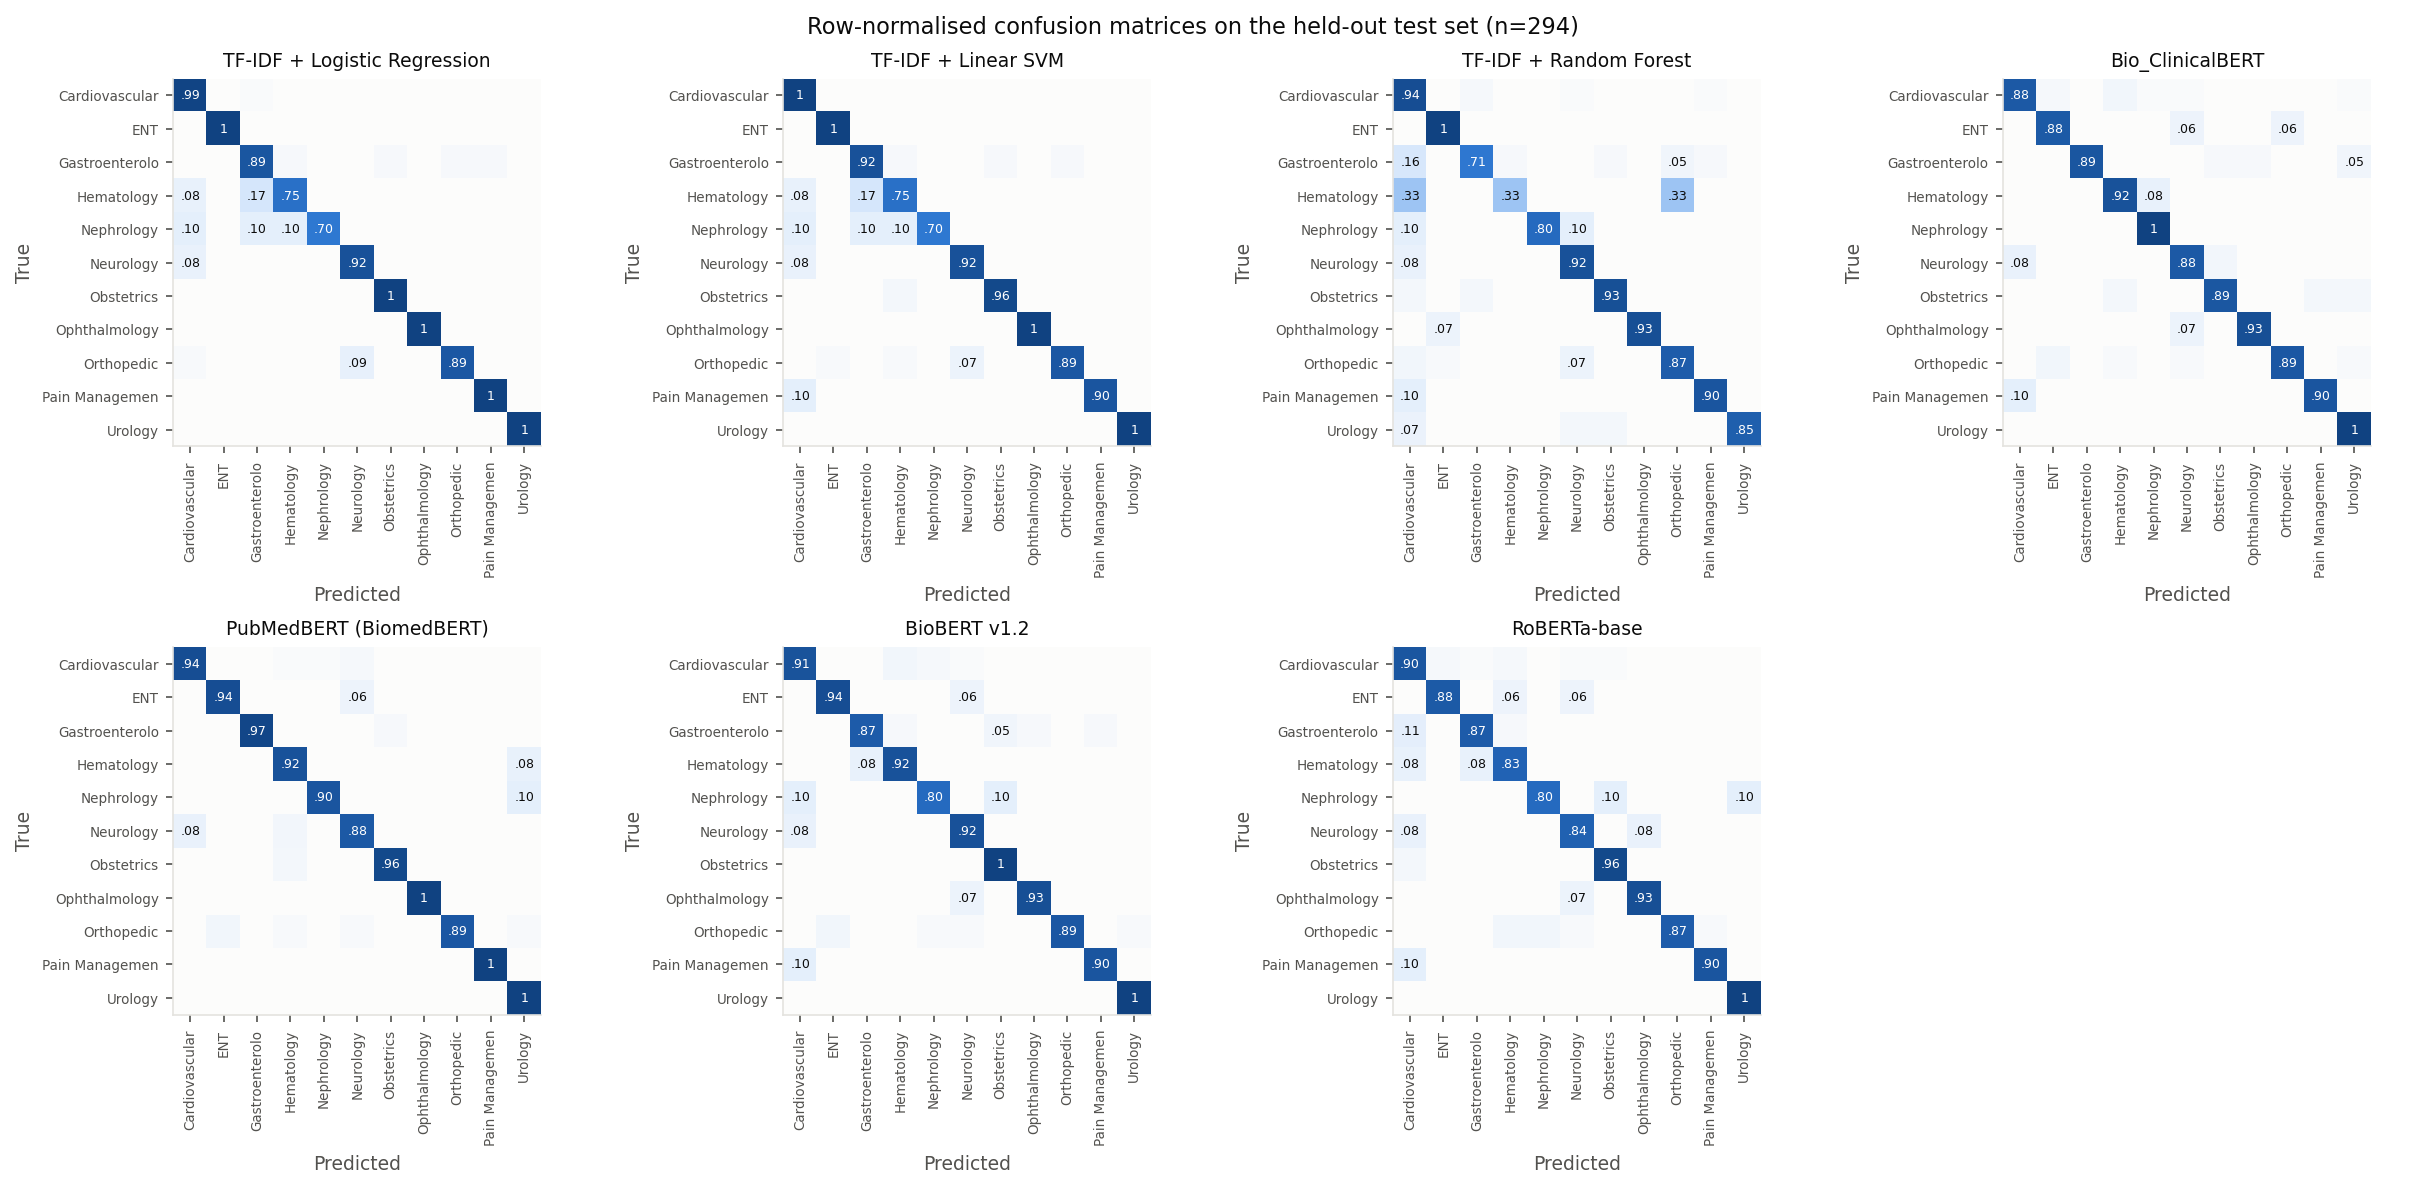

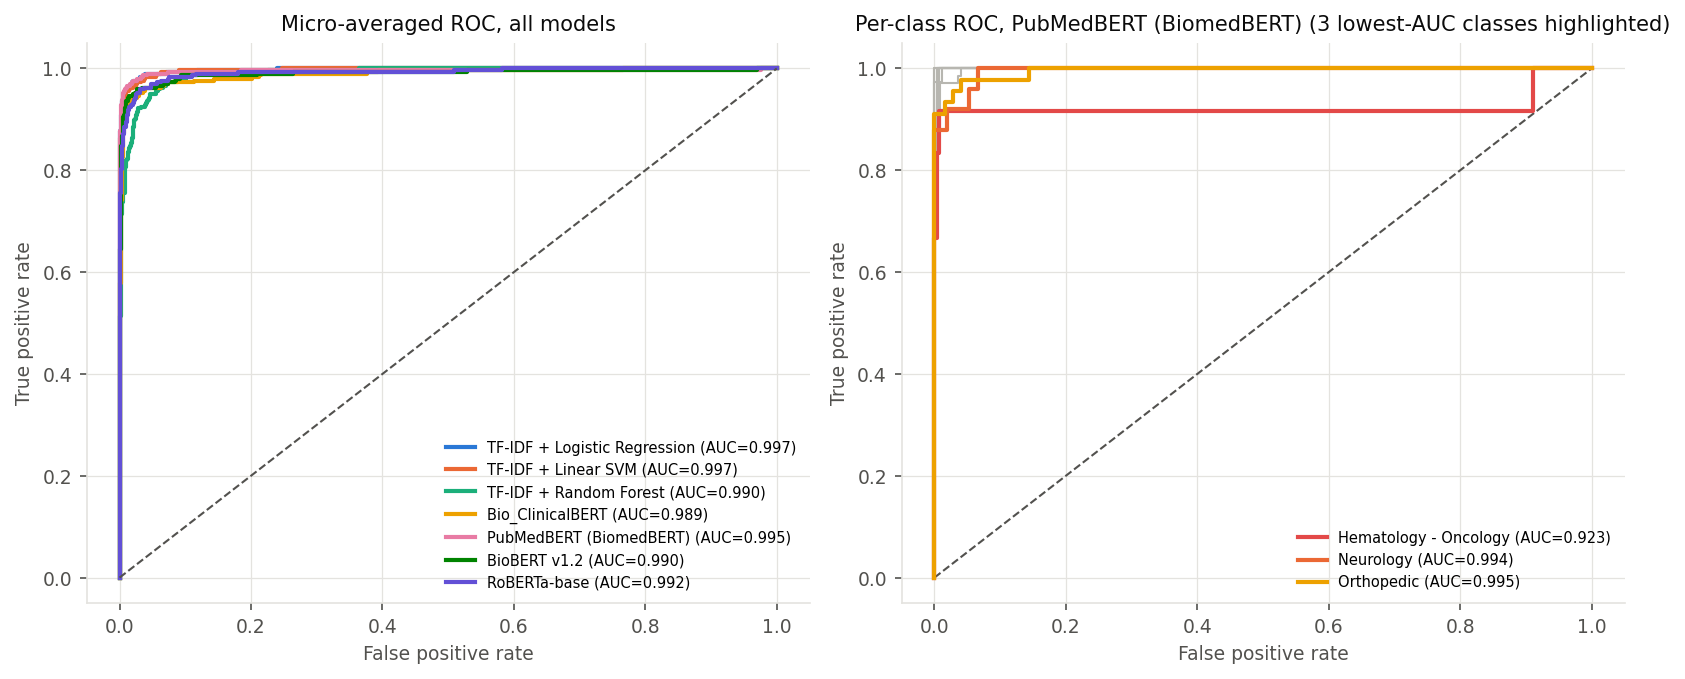

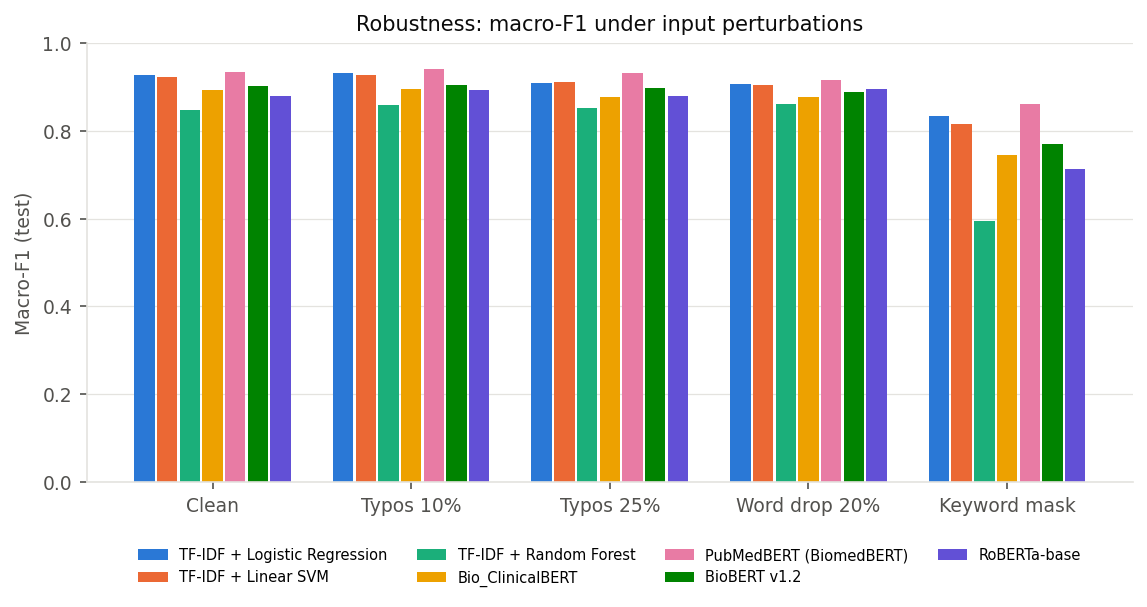

In [6]:
from src import analysis
analysis.main(run_cv=RUN_CV)
display(pd.read_csv(T / "performance.csv"))
display(pd.read_csv(T / "robustness.csv"))
display(pd.read_csv(T / "fairness.csv"))
display(pd.read_csv(T / "counterfactual_gender_swap.csv"))
for figure in ("confusion_matrices.png", "roc_curves.png", "robustness.png"):
    display(Image(filename=str(F / figure)))

**Observations**

- PubMedBERT correctly labels 277 of 294 notes, reaching macro-F1 0.9347. Logistic Regression labels 276 correctly with macro-F1 0.9280, a difference of one correct specialty label.
- Unseen-specialty AUROC favors Logistic Regression, 0.9139 versus 0.8414. PubMedBERT accepts 65.95% of unseen notes at the reported threshold, compared with 45.88% for the linear baseline.

## Step 6. Evaluation continued: computational efficiency and interpretability

### Computational efficiency

Each model was measured in a fresh process on the same CPU. After one warm-up call, latency was recorded for 30 individual notes and throughput for a batch of 64. Timing includes feature extraction or tokenization, starting with cleaned text; PHI screening and normalization are excluded. File size and peak memory are expressed in MiB, using division by 2²⁰, despite the CSV columns being labeled MB.


| Model | latency median (ms) | latency p95 (ms) | throughput (docs/s) | peak memory (MiB) | serialized size (MiB) |
|---|---|---|---|---|---|
| TF-IDF + Logistic Regression | 1.09 | 1.85 | 3145.80 | 155.26 | 0.81 |
| TF-IDF + Linear SVM | 4.31 | 5.35 | 2896.48 | 161.05 | 4.17 |
| TF-IDF + Random Forest | 74.73 | 95.48 | 451.67 | 200.51 | 5.72 |
| Bio_ClinicalBERT | 419.07 | 634.80 | 2.51 | 818.58 | 413.27 |
| PubMedBERT (BiomedBERT) | 613.52 | 975.50 | 2.31 | 863.86 | 417.74 |
| BioBERT v1.2 | 528.91 | 658.34 | 1.85 | 899.86 | 413.27 |
| RoBERTa-base | 450.96 | 651.54 | 2.49 | 902.75 | 475.58 |
| PubMedBERT (BiomedBERT) (int8) | 343.60 | 517.33 | 3.23 | 1170.42 | 173.08 |



*Table 10. Hardware-specific saved inference records. Peak memory includes interpreter, libraries, loading, and temporary allocations; it is not isolated resident weight memory.*

Median latency is 1.09 ms for Logistic Regression and 613.52 ms for PubMedBERT, about 562 times longer. Those numbers describe the systems as implemented, including their different input lengths. Size comparisons need care: classical files are compressed joblib pipelines, while transformer files are state dictionaries that exclude tokenizers and software dependencies. Only one machine and one measurement sequence were used; there are no uncertainty intervals or concurrent-load tests.

Caching and tuning took roughly 142.2 minutes for Bio_ClinicalBERT, 110.1 for PubMedBERT, 122.2 for BioBERT, and 84.1 for RoBERTa. These totals include caching evaluation and corrupted inputs. Classical grid searches took 1.45, 0.35, and 5.83 minutes for Logistic Regression, SVM, and Random Forest. The SVM timer excludes later calibration, so these totals cover different amounts of work.

For every transformer, the end-to-end float32 implementation matches the cached pipeline's predicted labels on all 294 test notes. The probabilities can still differ, and agreement on this set does not guarantee agreement on new notes.

Dynamic int8 quantization cuts PubMedBERT's median latency from 613.52 to 343.60 ms and its stored state from 417.74 to 173.08 MiB. The cost is substantial: macro-F1 falls from 0.9347 to 0.8813, and peak process memory rises from 863.86 to 1,170.42 MiB. This version would sacrifice accuracy for speed. Its packed weights also change what `.parameters()` counts, making the apparent parameter reduction unsuitable as evidence of architectural compression.

### Interpretability

Linear SHAP explains Logistic Regression against a background of 500 training documents. The contributions sum in raw class-logit space. They do not describe changes in predicted probability or binary log-odds against all other classes. The chosen background and correlations between TF-IDF features affect their interpretation (Lundberg & Lee, 2017).

![Figure 8. Linear SHAP importance for Logistic Regression, expressed in raw class-logit units.](../results/figures/shap_logreg.png)

Two selected notes illustrate PubMedBERT explanations: one correct prediction and one error. SHAP Partition uses up to 500 evaluations per note. LIME uses 300 perturbations for the transformer and 1,000 for Logistic Regression. Explanations follow each model's input scope: the prefix for PubMedBERT, the full note for the baseline. LIME fits a local approximation to model behavior (Ribeiro et al., 2016).

![Figure 9. Local SHAP and LIME explanations for test notes 0 and 73. Blue supports the displayed class; orange opposes it.](../results/figures/local_explanations.png)

Note 73 shows the risk clearly. Its label is Hematology - Oncology, yet PubMedBERT predicts Urology with probability 0.9956. Logistic Regression also gets it wrong, choosing Gastroenterology at 0.3194. A clinician would need to examine the note, its label, and the explanations to judge the error. These two examples cannot establish explanation quality across the dataset.

![Figure 10. Last-layer attention for one selected note. Attention visualizes model computation but does not establish a faithful explanation.](../results/figures/attention.png)

The attention plot is shown as a view of model computation. Attention weights alone can fail to explain a prediction faithfully (Jain & Wallace, 2019). The SHAP axes use class-logit units.

,model,Model,training/tuning time (min),training note,latency median (ms),latency p95 (ms),throughput (docs/s),peak memory (MB),serialized size (MB),parameters (M),test macro-F1 end-to-end,agreement w/ cached pipeline
0,logreg,TF-IDF + Logistic Regression,1.4501,"grid search, 5-fold CV",1.0920,1.8517,3145.7979,155.2617,0.8055,NaN,NaN,NaN
1,svm,TF-IDF + Linear SVM,0.3479,"grid search, 5-fold CV",4.3126,5.3453,2896.4781,161.0547,4.1667,NaN,NaN,NaN
2,rf,TF-IDF + Random Forest,5.8254,"grid search, 5-fold CV",74.7277,95.4802,451.6670,200.5117,5.7241,NaN,NaN,NaN
3,clinicalbert,Bio_ClinicalBERT,142.1575,state caching + 2 LR configs,419.0747,634.7962,2.5147,818.5820,413.2663,108.3187,0.8936,1.0
4,pubmedbert,PubMedBERT (BiomedBERT),110.1157,state caching + 2 LR configs,613.5228,975.4960,2.3143,863.8633,417.7370,109.4907,0.9347,1.0
5,biobert,BioBERT v1.2,122.1788,state caching + 2 LR configs,528.9072,658.3416,1.8480,899.8633,413.2663,108.3187,0.9016,1.0
6,roberta,RoBERTa-base,84.0678,state caching + 2 LR configs,450.9600,651.5436,2.4935,902.7539,475.5808,124.6541,0.8799,1.0
7,pubmedbert_int8,PubMedBERT (BiomedBERT) (int8),110.1157,state caching + 2 LR configs,343.5994,517.3257,3.2341,1170.4219,173.0757,NaN,0.8813,NaN


,class,feature,mean |SHAP|,mean SHAP
0,Cardiovascular / Pulmonary,chest,0.1294,0.0142
1,Cardiovascular / Pulmonary,artery,0.0834,-0.0147
2,Cardiovascular / Pulmonary,coronary,0.0791,-0.0086
10,ENT - Otolaryngology,nasal,0.0680,0.0197
11,ENT - Otolaryngology,ear,0.0578,-0.0011
12,ENT - Otolaryngology,are,0.0336,0.0018
20,Gastroenterology,left,0.0595,-0.0032
21,Gastroenterology,abdominal,0.0593,-0.0075
22,Gastroenterology,bowel,0.0538,0.0012
30,Hematology - Oncology,cancer,0.0587,0.0135


,test_index,true,pred_transformer,p,pred_logreg
0,0,Cardiovascular / Pulmonary,Cardiovascular / Pulmonary,0.9990,Cardiovascular / Pulmonary
1,73,Hematology - Oncology,Urology,0.9956,Gastroenterology


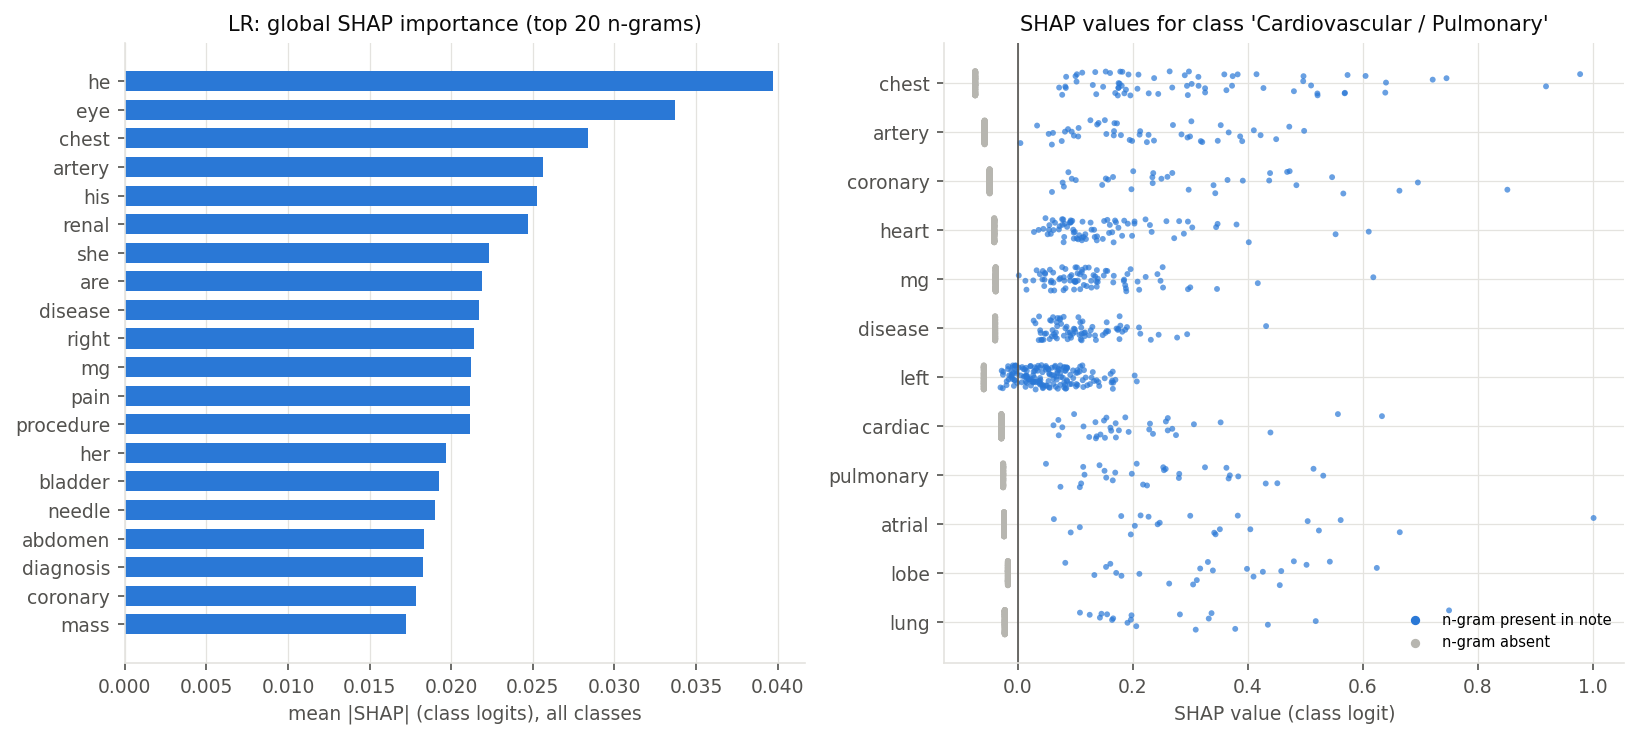

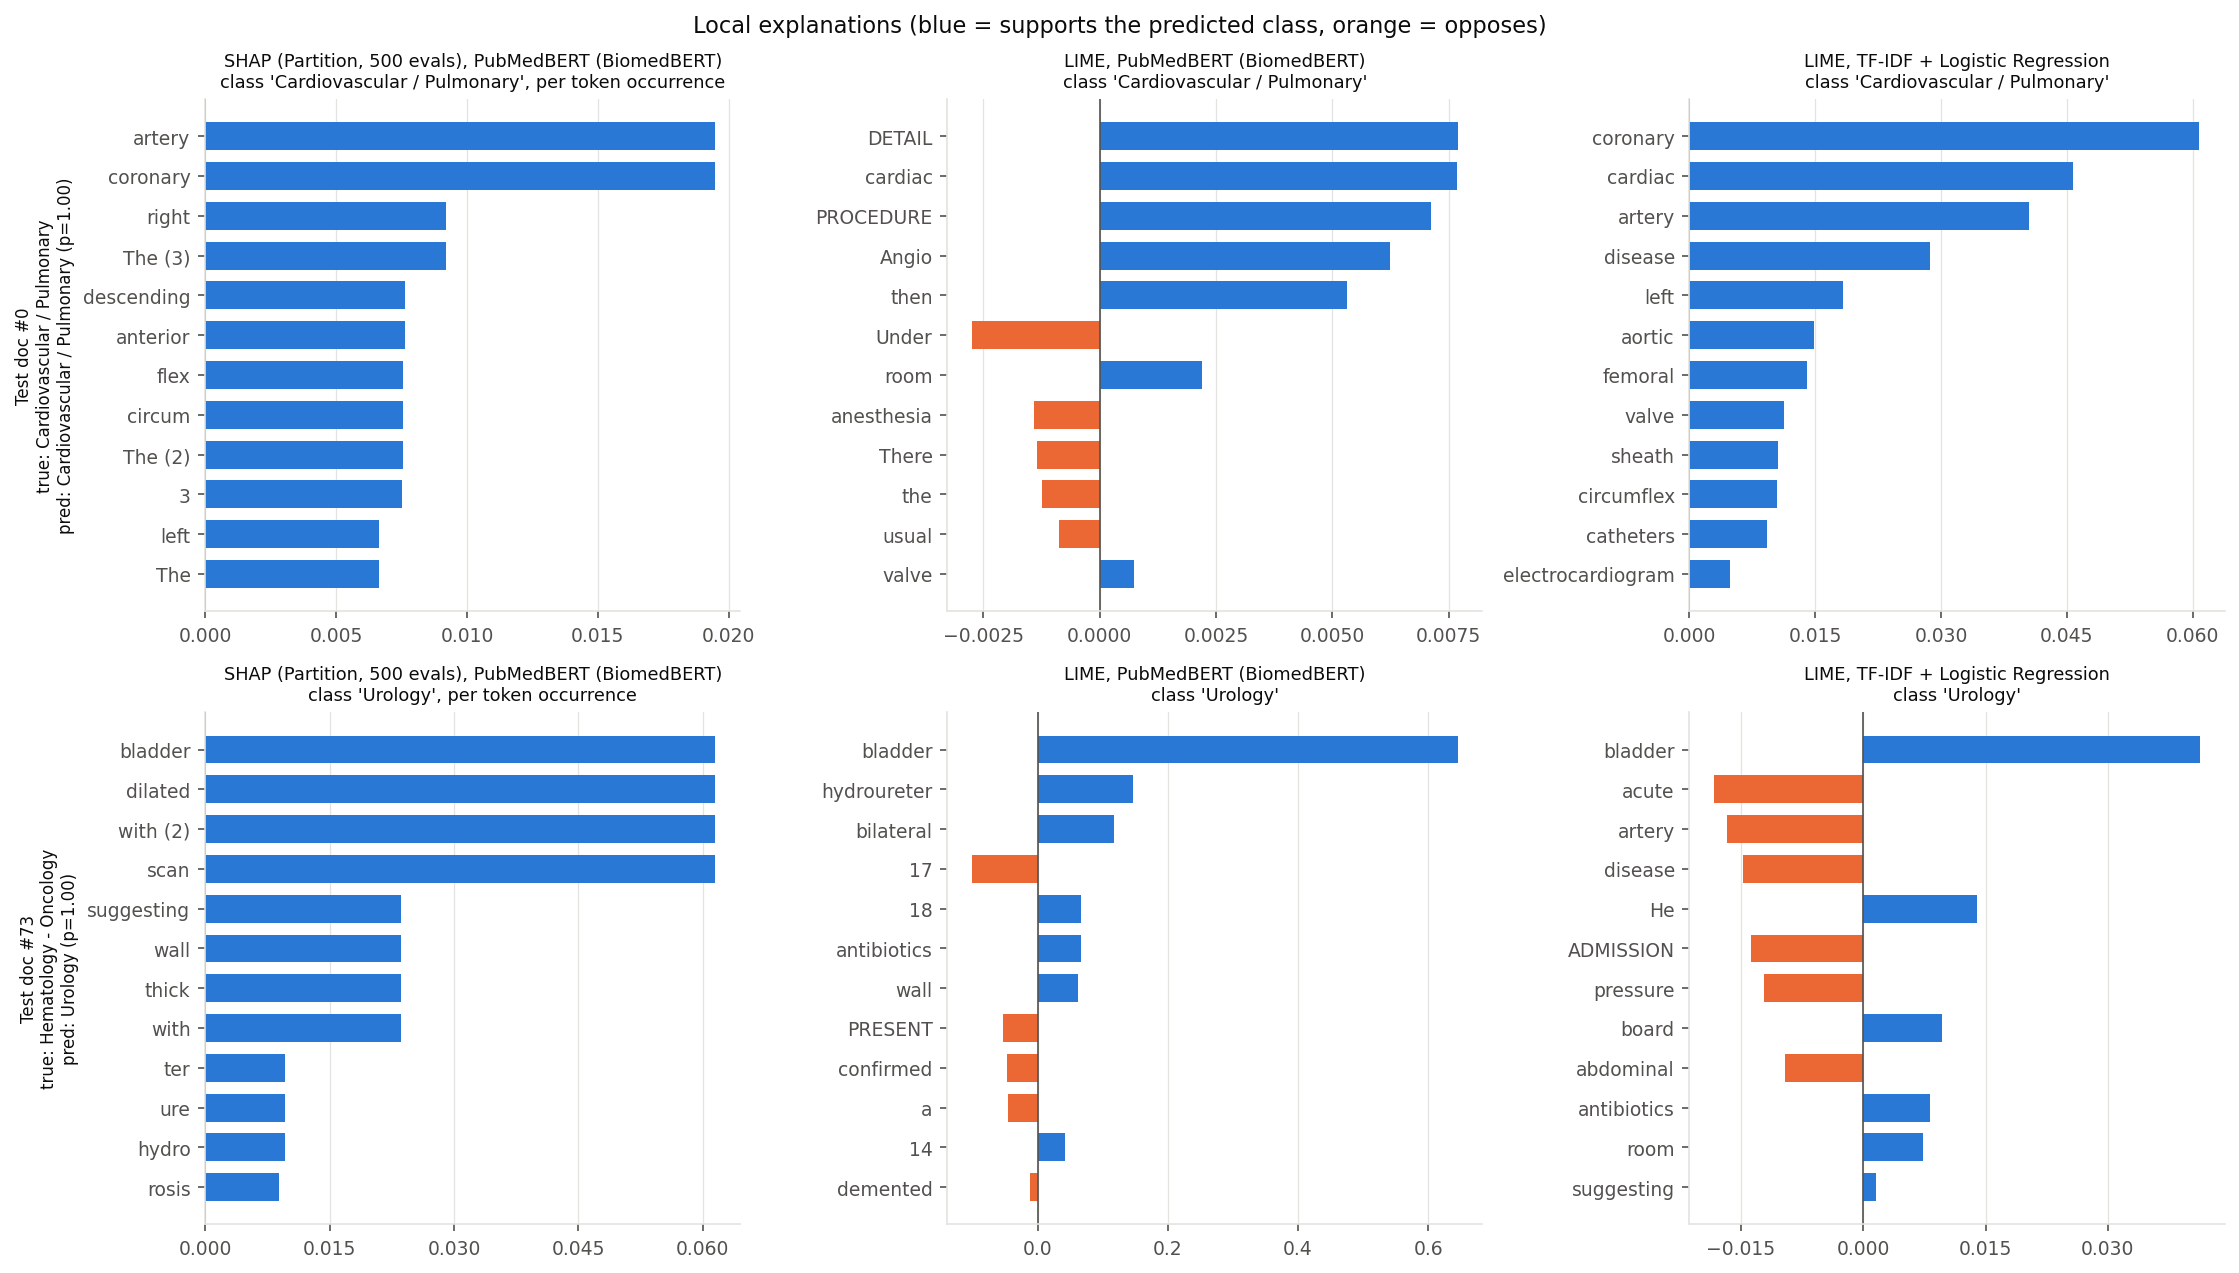

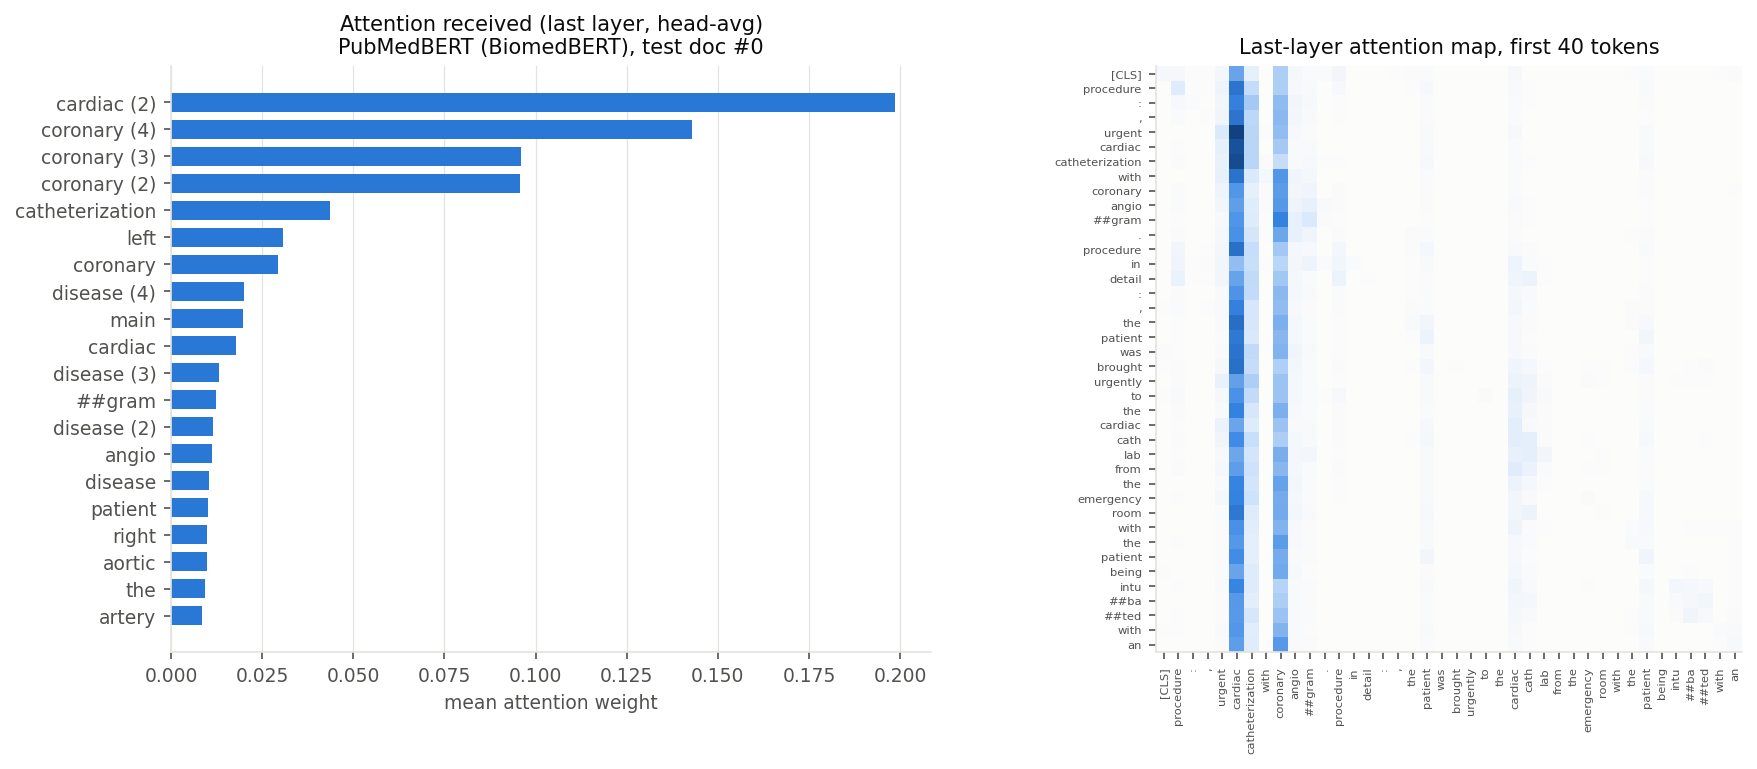

In [7]:
display(pd.read_csv(T / "efficiency.csv"))
display(pd.read_csv(T / "shap_logreg_top_features.csv").groupby("class", sort=False).head(3))
explanations = json.loads((ROOT / "results/local_explanations.json").read_text())
display(pd.DataFrame([{k: item[k] for k in ("test_index", "true", "pred_transformer", "p", "pred_logreg")}
                      for item in explanations]))
for figure in ("shap_logreg.png", "local_explanations.png", "attention.png"):
    display(Image(filename=str(F / figure)))

**Observations**

- Median inference takes 1.09 milliseconds for Logistic Regression and 613.52 for PubMedBERT. Their storage sizes are 0.81 and 417.74 MiB, though serialization formats differ.
- Quantized PubMedBERT reaches 343.60 milliseconds and 173.08 MiB, but macro-F1 drops to 0.8813. Peak memory rises to 1,170.42 MiB, exceeding the original model's process memory usage.

## Step 7. Optimization and statistical comparison

Validation macro-F1 selects the reference model. PubMedBERT leads at 0.9358, followed by SVM at 0.9333 and Logistic Regression at 0.9304. The code follows this rule, but saved files cannot establish whether developers ever inspected the test set. No preregistration is available to support a stronger claim about the comparison protocol.

McNemar's test compares whether the models get the same notes right or wrong. Fewer than 25 discordant pairs trigger an exact binomial test; larger counts use continuity-corrected chi-square. Holm correction covers all 21 pairs. Only three adjusted comparisons fall below p = .05: Logistic Regression, SVM, and PubMedBERT each outperform Random Forest on accuracy. The remaining tests leave differences unresolved; they do not establish equivalence or test macro-F1.

| Accuracy comparison | First model correct / second wrong | First wrong / second correct | Raw p | Holm-adjusted p |
|---|---:|---:|---:|---:|
| Logistic Regression vs. PubMedBERT | 8 | 9 | 1.0000 | 1.0000 |
| SVM vs. PubMedBERT | 7 | 8 | 1.0000 | 1.0000 |
| Random Forest vs. PubMedBERT | 9 | 33 | 0.000387 | 0.007735 |
| PubMedBERT vs. RoBERTa | 18 | 4 | 0.004344 | 0.078183 |

*Table 11. Selected McNemar comparisons. The complete 21-pair table is `results/tables/mcnemar.csv`.*


| reference | vs | delta macro-F1 | 95% CI low | 95% CI high |
|---|---|---|---|---|
| pubmedbert | logreg | 0.0067 | -0.0300 | 0.0451 |
| pubmedbert | svm | 0.0126 | -0.0212 | 0.0500 |
| pubmedbert | rf | 0.0863 | 0.0346 | 0.1378 |
| pubmedbert | clinicalbert | 0.0411 | 0.0052 | 0.0821 |
| pubmedbert | biobert | 0.0330 | 0.0052 | 0.0660 |
| pubmedbert | roberta | 0.0548 | 0.0167 | 0.0939 |



*Table 12. Paired percentile-bootstrap differences: PubMedBERT macro-F1 minus comparator macro-F1, using 1,000 shared resamples. These six intervals are pointwise, without multiplicity adjustment.*

The paired macro-F1 interval for PubMedBERT minus Logistic Regression spans −0.0300 to 0.0451 around a difference of 0.0067. The SVM interval also crosses zero. Intervals against some weaker models exclude zero, but these use macro-F1 without multiplicity adjustment, unlike the McNemar tests. The CSV field `P(delta<=0)` counts bootstrap samples with nonpositive differences. It is neither a calibrated p-value nor a posterior probability and is omitted from Table 12.

Resampling uses the 1,172 training and validation documents, excluding the held-out test set. Dietterich's five-by-two paired t-test and a Nadeau–Bengio-style correction for ten-fold scores account approximately for dependence between fitted comparisons (Dietterich, 1998; Nadeau & Bengio, 2003). Treating correlated fold scores as independent would make the estimates appear too precise.


| model | 5x2cv mean | 5x2cv sd | 10-fold mean | 10-fold sd |
|---|---|---|---|---|
| logreg | 0.8847 | 0.0088 | 0.9048 | 0.0267 |
| svm | 0.8945 | 0.0101 | 0.9125 | 0.0261 |
| rf | 0.8027 | 0.0162 | 0.8386 | 0.0377 |
| clinicalbert_frozen | 0.8048 | 0.0107 | 0.8296 | 0.0246 |
| pubmedbert_frozen | 0.8416 | 0.0119 | 0.8561 | 0.0287 |
| biobert_frozen | 0.8034 | 0.0210 | 0.8268 | 0.0218 |
| roberta_frozen | 0.7925 | 0.0118 | 0.8045 | 0.0331 |



*Table 13. Resampled macro-F1 means and standard deviations. Each `_frozen` row is an unfine-tuned transformer representation with a standardized Logistic Regression probe; it is not the corresponding final transformer classifier.*

SVM leads the ten-fold comparison at 0.9125; Logistic Regression follows at 0.9048. Their raw p-values are 0.5440 for five-by-two and 0.2168 for corrected ten-fold testing, with both adjusted to 1.000. Hyperparameters were selected earlier using overlapping data, so these are not nested estimates of the full tuning procedure. SVM resampling also uses the uncalibrated classifier, whereas the test results use the calibrated ensemble. Frozen transformer probes leave fine-tuning stability untested.

Both PubMedBERT and Logistic Regression merit further testing. The former has the highest observed macro-F1; the latter costs far less to run. The int8 result rules out assuming that compression preserves performance. Longer inputs, full fine-tuning, temperature scaling, ensembles, and alternative OOD detectors remain experiments to run.

![Figure 11. Observed test macro-F1 versus median CPU latency. These measurements support a trade-off, not a statistically established universal winner.](../results/figures/tradeoff.png)

validation_selection


,Unnamed: 0,validation macro-F1
0,TF-IDF + Logistic Regression,0.9304
1,TF-IDF + Linear SVM,0.9333
2,TF-IDF + Random Forest,0.8725
3,Bio_ClinicalBERT,0.9096
4,PubMedBERT (BiomedBERT),0.9358
5,BioBERT v1.2,0.8863
6,RoBERTa-base,0.8533


mcnemar


,A,B,A right/B wrong,A wrong/B right,test,statistic,p,p (Holm)
0,logreg,svm,3,3,exact,3.0000,1.0000,1.0000
1,logreg,rf,29,6,chi2 (cc),13.8286,0.0002,0.0042
2,logreg,clinicalbert,19,9,chi2 (cc),2.8929,0.0890,1.0000
3,logreg,pubmedbert,8,9,exact,8.0000,1.0000,1.0000
4,logreg,biobert,13,7,exact,7.0000,0.2632,1.0000
5,logreg,roberta,21,8,chi2 (cc),4.9655,0.0259,0.3879
6,svm,rf,31,8,chi2 (cc),12.4103,0.0004,0.0081
7,svm,clinicalbert,18,8,chi2 (cc),3.1154,0.0776,1.0000
8,svm,pubmedbert,7,8,exact,7.0000,1.0000,1.0000
9,svm,biobert,12,6,exact,6.0000,0.2379,1.0000


paired_bootstrap


,reference,vs,delta macro-F1,95% CI low,95% CI high,P(delta<=0)
0,pubmedbert,logreg,0.0067,-0.0300,0.0451,0.336
1,pubmedbert,svm,0.0126,-0.0212,0.0500,0.226
2,pubmedbert,rf,0.0863,0.0346,0.1378,0.000
3,pubmedbert,clinicalbert,0.0411,0.0052,0.0821,0.013
4,pubmedbert,biobert,0.0330,0.0052,0.0660,0.009
5,pubmedbert,roberta,0.0548,0.0167,0.0939,0.003


... (3 outputs left out)

,A,B,mean diff (10-fold),5x2cv t,5x2cv p,corrected t (10-fold),corrected p (10-fold),5x2cv p (Holm),corrected p (Holm)
0,logreg,svm,-0.0076,-0.6507,0.5440,-1.3281,2.1683e-01,1.0000,1.0000
1,logreg,rf,0.0662,4.5729,0.0060,3.4651,7.1031e-03,0.0778,0.0923
2,logreg,clinicalbert_frozen,0.0753,10.3235,0.0001,5.2607,5.2027e-04,0.0031,0.0088
3,logreg,pubmedbert_frozen,0.0487,5.2142,0.0034,3.0806,1.3127e-02,0.0514,0.1444
4,logreg,biobert_frozen,0.0780,5.4789,0.0028,6.8437,7.5262e-05,0.0442,0.0014
5,logreg,roberta_frozen,0.1003,6.1969,0.0016,8.1088,1.9868e-05,0.0303,0.0004
6,svm,rf,0.0738,5.0085,0.0041,3.4474,7.3048e-03,0.0570,0.0923
7,svm,clinicalbert_frozen,0.0829,5.9231,0.0020,5.2493,5.2821e-04,0.0352,0.0088
8,svm,pubmedbert_frozen,0.0563,5.5679,0.0026,3.6225,5.5503e-03,0.0437,0.0777
9,svm,biobert_frozen,0.0856,4.2740,0.0079,7.2336,4.9020e-05,0.0949,0.0009


tradeoff


,Model,Macro-F1,ECE,Macro-F1 under keyword mask,OOD AUROC (MSP),latency median (ms),throughput (docs/s),peak memory (MB),serialized size (MB),interpretability
0,TF-IDF + Logistic Regression,0.9280,0.1166,0.8346,0.9139,1.0920,3145.7979,155.2617,0.8055,intrinsic (exact linear SHAP)
1,TF-IDF + Linear SVM,0.9221,0.1502,0.8146,0.9009,4.3126,2896.4781,161.0547,4.1667,intrinsic (linear weights)
2,TF-IDF + Random Forest,0.8484,0.3779,0.5945,0.8702,74.7277,451.6670,200.5117,5.7241,post-hoc (tree SHAP possible)
3,Bio_ClinicalBERT,0.8936,0.0325,0.7452,0.8134,419.0747,2.5147,818.5820,413.2663,"post-hoc only (LIME/SHAP, approx.)"
4,PubMedBERT (BiomedBERT),0.9347,0.0354,0.8615,0.8414,613.5228,2.3143,863.8633,417.7370,"post-hoc only (LIME/SHAP, approx.)"
5,BioBERT v1.2,0.9016,0.0549,0.7696,0.8296,528.9072,1.8480,899.8633,413.2663,"post-hoc only (LIME/SHAP, approx.)"
6,RoBERTa-base,0.8799,0.0587,0.7121,0.8107,450.9600,2.4935,902.7539,475.5808,"post-hoc only (LIME/SHAP, approx.)"


Bootstrap tail fractions are descriptive, not calibrated p-values.
CV transformer rows use frozen representation probes, not fine-tuned models.


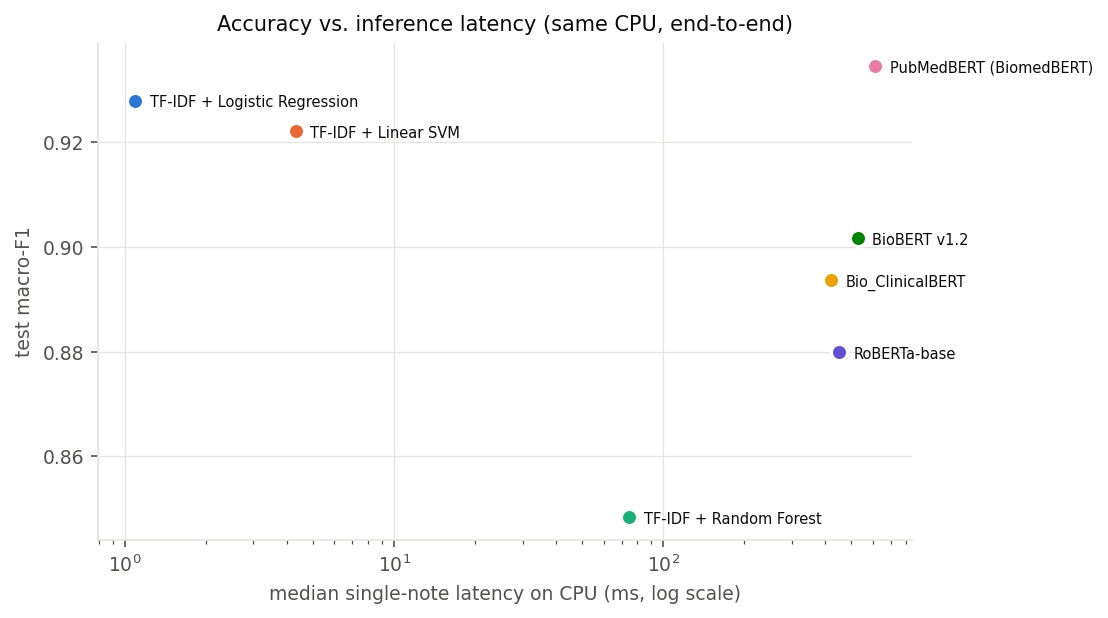

In [8]:
for name in ("validation_selection", "mcnemar", "paired_bootstrap", "cv_summary", "cv_tests", "tradeoff"):
    print(name)
    display(pd.read_csv(T / f"{name}.csv"))
print("Bootstrap tail fractions are descriptive, not calibrated p-values.")
print("CV transformer rows use frozen representation probes, not fine-tuned models.")
display(Image(filename=str(F / "tradeoff.png")))

**Observations**

- PubMedBERT exceeds Logistic Regression by 0.0067 macro-F1, with a paired interval from −0.0300 to 0.0451. Their Holm-adjusted McNemar p-value is 1.000, leaving superiority unresolved.
- Ten-fold macro-F1 averages are 0.9125 for SVM and 0.9048 for Logistic Regression. Both adjusted paired-test p-values equal 1.000; these resampling outputs do not establish a difference.

## Step 8. Reporting, error analysis, and clinical implications

### Error analysis

PubMedBERT misclassifies 17 test notes. Its mean maximum probability on errors is 0.7821, and six errors exceed 0.90 confidence; correct predictions average 0.9860. Three confusion directions each occur twice: Cardiovascular / Pulmonary to Neurology, the reverse direction, and Orthopedic to ENT - Otolaryngology. Explaining why requires clinicians to review the individual notes.


| Specialty | TF-IDF + Logistic Regression | PubMedBERT (BiomedBERT) | support |
|---|---|---|---|
| Cardiovascular / Pulmonary | 0.9571 | 0.9552 | 68 |
| ENT - Otolaryngology | 1.0000 | 0.9091 | 16 |
| Gastroenterology | 0.8947 | 0.9867 | 38 |
| Hematology - Oncology | 0.7826 | 0.8148 | 12 |
| Nephrology | 0.8235 | 0.9000 | 10 |
| Neurology | 0.8846 | 0.8627 | 25 |
| Obstetrics / Gynecology | 0.9825 | 0.9643 | 28 |
| Ophthalmology | 1.0000 | 1.0000 | 15 |
| Orthopedic | 0.9302 | 0.9412 | 45 |
| Pain Management | 0.9524 | 1.0000 | 10 |
| Urology | 1.0000 | 0.9474 | 27 |



*Table 14. Per-specialty F1 for the leading baseline and transformer, with test support. Perfect F1 on small samples does not imply perfect clinical performance.*

Hematology - Oncology has only 12 test notes. F1 is 0.8148 for PubMedBERT and 0.7826 for Logistic Regression. PubMedBERT does well on Gastroenterology; the linear model scores higher on ENT and Urology. Model choice may depend on which specialties a service receives most often and which errors it can tolerate.

### Ethical reliability and clinical relevance

No part of this experiment measures treatment decisions, patient outcomes, or benefit to clinicians. Ambiguous cases were excluded, privacy screening remains incomplete, and demographics were inferred from text. Shared templates, near duplicates, and overlap with pre-training material could affect the scores. The study has no external-site, temporal, prospective, or clinical workflow validation.

The World Health Organization's [ethics and governance guidance](https://www.who.int/publications/i/item/9789240029200) calls for human oversight, transparency, accountability, and equity (World Health Organization, 2021). In a routing service, staff would need to know when a prediction is uncertain, correct misrouted notes, and reject an output when necessary. The present evaluation establishes neither ethical certification nor regulatory compliance.

### Requirement coverage and remaining limitations

| Assignment requirement | Evidence | Review conclusion |
|---|---|---|
| Labeled medical text collection | Raw CSV, reproducible label audit and splits | Specialty classification supported; diagnosis-support outcomes unavailable |
| Preprocessing, imbalance handling, stratified splits | `src/data.py`, class weights, tokenizer audit | Implemented; complete PHI removal and abbreviation correctness unverified |
| At least four architectures | Three classical models and four transformers | Met |
| Hyperparameter search and tracking | Classical grids, two transformer learning rates, MLflow histories | Implemented within limited search budgets |
| Early stopping and clipping | Transformer training code and histories | Met where applicable |
| Cross-validation | Classical grids, five-by-two and ten-fold analyses, frozen probes | Partial for final fine-tuned transformers; nested tuning absent |
| Accuracy, precision, recall, F1, ROC-AUC | Saved probabilities and metric tables | Recomputed and checked |
| Robustness and adversarial examples | Heuristic corruptions, targeted keyword masking, unseen labels | Implemented with limitations; no optimized semantic-preserving attack |
| Fairness | DP, EO, subgroup scores, gendered-word swaps | Exploratory proxy audit; insufficient to establish fairness |
| Efficiency and interpretability | Timing records, sizes, SHAP, LIME, attention | Available; timing not repeated; transformer explanations cover two notes |
| Statistical optimization | McNemar, paired bootstrap, corrected CV tests, quantization | Available; leading-model superiority not established |
| Technical report | Required narrative sections, comparison tables, charts, references | Report format covered; remaining experimental gaps listed above; separate rubric unavailable |

The notebook loads saved predictions and recalculates evaluation results. Its executed cells document that process, without rerunning transformer training. Raw data, model weights, and MLflow records are local files excluded by `.gitignore`; another researcher would need those files or a new training run. `requirements.txt` pins software versions, but checkpoint revisions remain unpinned, which limits exact reproduction after future model-hub changes.

In [9]:
from src.review import main as audit_saved_evidence
audit_saved_evidence()
summary = json.loads((ROOT / "results/analysis_summary.json").read_text())
print(json.dumps(summary, indent=2))
display(pd.read_csv(T / "error_pairs_pubmedbert.csv"))
display(pd.read_csv(T / "per_class_f1.csv"))
print("No diagnostic or prospective clinical outcome evaluation was performed.")

{
  "passed": 359,
  "failed": 0,
  "validation_selected_model": "pubmedbert",
  "mlflow": {
    "run_status_counts": {
      "FINISHED": 18,
      "RUNNING": 1
    },
    "metric_records": 399
  }
}
{
  "best_overall": "pubmedbert",
  "best_transformer": "pubmedbert",
  "error_analysis": {
    "n_errors": 17,
    "mean_conf_wrong": 0.7821481227874756,
    "mean_conf_right": 0.9860237240791321,
    "errors_conf_gt_0.9": 6
  }
}


,Unnamed: 0,count
0,Cardiovascular / Pulmonary -> Neurology,2
1,Orthopedic -> ENT - Otolaryngology,2
2,Neurology -> Cardiovascular / Pulmonary,2
3,Hematology - Oncology -> Urology,1
4,Neurology -> Hematology - Oncology,1
5,Obstetrics / Gynecology -> Hematology - Oncology,1
6,Nephrology -> Urology,1
7,Orthopedic -> Hematology - Oncology,1
8,Cardiovascular / Pulmonary -> Nephrology,1
9,ENT - Otolaryngology -> Neurology,1


,Unnamed: 0,TF-IDF + Logistic Regression,TF-IDF + Linear SVM,TF-IDF + Random Forest,Bio_ClinicalBERT,PubMedBERT (BiomedBERT),BioBERT v1.2,RoBERTa-base,TF-IDF + LR (first 256 tokens),support
0,Cardiovascular / Pulmonary,0.9571,0.9645,0.8477,0.9160,0.9552,0.9254,0.8841,0.9143,68
1,ENT - Otolaryngology,1.0000,0.9697,0.9412,0.8235,0.9091,0.9091,0.8750,0.8571,16
2,Gastroenterology,0.8947,0.9211,0.7941,0.9444,0.9867,0.9167,0.9041,0.8684,38
3,Hematology - Oncology,0.7826,0.7200,0.4706,0.7857,0.8148,0.8148,0.7143,0.7857,12
4,Nephrology,0.8235,0.8235,0.8889,0.9091,0.9000,0.7619,0.8000,0.8889,10
5,Neurology,0.8846,0.9020,0.8519,0.8627,0.8627,0.8846,0.8400,0.8000,25
6,Obstetrics / Gynecology,0.9825,0.9643,0.9286,0.9091,0.9643,0.9492,0.9474,0.9630,28
7,Ophthalmology,1.0000,1.0000,0.9655,0.9333,1.0000,0.9333,0.9032,0.8571,15
8,Orthopedic,0.9302,0.9302,0.8667,0.9302,0.9412,0.9412,0.9286,0.8864,45
9,Pain Management,0.9524,0.9474,0.8571,0.9000,1.0000,0.9000,0.9000,0.8889,10


No diagnostic or prospective clinical outcome evaluation was performed.


**Observations**

- PubMedBERT makes 17 test errors, including six above 0.90 confidence. Mean prediction confidence is 0.7821 on errors, compared with 0.9860 on correctly classified notes.
- Hematology and Oncology F1 is 0.8148 for PubMedBERT and 0.7826 for Logistic Regression on 12 notes. The linear model scores higher on ENT and Urology specialties.

## Discussion

The main choice is between a small measured gain in classification and a large difference in running cost. PubMedBERT gets one more test label right than either linear baseline. Its paired macro-F1 interval still allows an advantage for Logistic Regression. A service choosing between them would need to decide what an additional correct routing decision is worth and test that assumption on a larger sample.

PubMedBERT handles keyword masking better and has lower ECE than Logistic Regression. The linear model is faster, occupies less storage, and separates unseen specialties more successfully. Neither result settles whether staff could use the model safely: the data contain no observations of actual routing decisions, corrections, delays, or harm.

The largest changes to the study happen before classification. Duplicate grouping reduces 4,966 nonmissing rows to 2,357 unique texts, and label filtering narrows the main task further. What remains is a useful comparison of these systems on selected MTSamples notes. Ambiguous cases, new hospitals, and variation between training runs still need their own evaluation.

## Final insights

- PubMedBERT produced the highest test macro-F1, 0.9347, and accuracy, 94.22%, correctly labeling 277 of 294 notes. Logistic Regression and SVM each classified 276 correctly. The difference amounts to one note, and the paired confidence interval crosses zero, leaving the apparent advantage over the linear baselines statistically unresolved on this dataset.
- Robustness depended on the failure being tested. Keyword masking reduced PubMedBERT's macro-F1 to 0.8615 and Logistic Regression's to 0.8346. For unseen specialties, Logistic Regression achieved AUROC 0.9139 against PubMedBERT's 0.8414. Their acceptance rates for unseen notes, 45.88% and 65.95%, show substantial remaining risk when the correct specialty is unavailable.
- The fairness outputs describe only part of the test population. PubMedBERT accuracy was 91.01% for female-coded notes and 93.41% for male-coded notes. Sex-proxy equal-opportunity gaps reached 0.1667. Unknown age affected 162 notes, and only four classes supported sex comparisons, preventing conclusions about fairness across all specialties or demographic groups.
- Logistic Regression required 1.09 milliseconds per note at the median, compared with 613.52 milliseconds for PubMedBERT. Quantization lowered transformer latency to 343.60 milliseconds and storage to 173.08 MiB, but macro-F1 dropped to 0.8813 and peak memory increased to 1,170.42 MiB. The smaller saved model did not deliver equivalent predictive performance.
- Explanation outputs identify associations and specific mistakes. Logistic Regression's cardiovascular SHAP ranking emphasized chest, artery, and coronary. PubMedBERT assigned Urology to an oncology note with probability 0.9956. Six of its 17 errors exceeded 0.90 confidence. Two local explanation examples cannot establish faithful reasoning, and high confidence did not guarantee a correct specialty.
- Class-level results vary beneath the aggregate ranking. Hematology and Oncology F1 reached 0.8148 for PubMedBERT versus 0.7826 for Logistic Regression on 12 notes. The linear model scored higher for ENT and Urology. These outputs support retaining both candidates for specialty-routing evaluation; they provide no measured diagnostic accuracy or patient benefit.

## Recommendations

1. Retain PubMedBERT and Logistic Regression for the next comparison. Their macro-F1 difference is 0.0067 with an interval crossing zero, so the current ranking cannot justify dropping the linear model. A larger external test set and repeated training seeds would help determine whether the small advantage persists.
2. For a supervised routing trial after external validation, assess Logistic Regression first when CPU latency matters: 1.09 milliseconds per note is much lower than PubMedBERT's 613.52. Measure actual misrouting costs alongside speed before selecting either model for a service.
3. Address unseen-specialty rejection before automating routing. PubMedBERT accepts 65.95% of unseen notes at the reported operating point, and Logistic Regression accepts 45.88%. Use separate validation data to set abstention thresholds and report the error rate among accepted notes as well as the review workload.
4. Do not adopt the tested int8 version on speed alone. Its macro-F1 falls from 0.9347 to 0.8813 while peak memory increases. Any revised compression method needs a fresh accuracy, latency, and memory comparison against the uncompressed model.
5. Prioritize clinical review of the 17 PubMedBERT errors, especially the six above 0.90 confidence and the oncology note assigned to Urology at 0.9956. Hematology - Oncology has only 12 test notes and F1 0.8148, making more labeled examples and class-specific error analysis a priority.
6. Revisit the subgroup results using verified demographics. Age is unknown for 162 notes, and sex-proxy equal-opportunity comparisons cover only four classes. Report uncertainty and missingness before interpreting the observed 91.01% versus 93.41% accuracy gap as evidence about patient equity.
7. Test longer transformer inputs because truncating Logistic Regression reduces macro-F1 from 0.9280 to 0.8811. Keep the input scope explicit and repeat the calibrated SVM pipeline within cross-validation; its 0.9125 resampling mean currently describes an uncalibrated classifier.
8. Check privacy-screening failures alongside its recorded 880 date, 334 name, and one phone substitutions. Those outputs count matches without measuring missed identifiers. The available outputs also contain no diagnostic accuracy or patient outcomes; evaluating diagnosis support requires a separate clinically adjudicated target and prospective evidence.

## Conclusions

PubMedBERT ranks first on test macro-F1, at 0.9347, and reaches 94.22% accuracy under partial fine-tuning. The paired tests do not establish an advantage over Logistic Regression or SVM. Logistic Regression reaches macro-F1 0.9280 with much lower CPU latency and better unseen-specialty detection.

Both models are candidates for further specialty-routing research. Neither has been validated for diagnosis or autonomous clinical use. The next decision should rest on external data and observed workflow errors, with privacy and demographic checks completed before patient care is affected.

## References

Alsentzer, E., Murphy, J., Boag, W., Weng, W.-H., Jin, D., Naumann, T., & McDermott, M. (2019). Publicly available clinical BERT embeddings. In *Proceedings of the 2nd Clinical Natural Language Processing Workshop* (pp. 72–78). Association for Computational Linguistics. https://doi.org/10.18653/v1/W19-1909

Devlin, J., Chang, M.-W., Lee, K., & Toutanova, K. (2019). BERT: Pre-training of deep bidirectional transformers for language understanding. In *Proceedings of NAACL-HLT 2019* (pp. 4171–4186). Association for Computational Linguistics. https://doi.org/10.18653/v1/N19-1423

Dietterich, T. G. (1998). Approximate statistical tests for comparing supervised classification learning algorithms. *Neural Computation, 10*(7), 1895–1923. https://doi.org/10.1162/089976698300017197

Gu, Y., Tinn, R., Cheng, H., Lucas, M., Usuyama, N., Liu, X., Naumann, T., Gao, J., & Poon, H. (2021). *Domain-specific language model pretraining for biomedical natural language processing* (arXiv:2007.15779, Version 6) [Preprint]. arXiv. https://doi.org/10.48550/arXiv.2007.15779

Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. In *Proceedings of the 34th International Conference on Machine Learning* (Vol. 70, pp. 1321–1330). PMLR. https://proceedings.mlr.press/v70/guo17a.html

Hardt, M., Price, E., & Srebro, N. (2016). *Equality of opportunity in supervised learning* (arXiv:1610.02413) [Preprint]. arXiv. https://arxiv.org/abs/1610.02413

Hendrycks, D., & Gimpel, K. (2017). *A baseline for detecting misclassified and out-of-distribution examples in neural networks*. International Conference on Learning Representations. https://arxiv.org/abs/1610.02136

Jain, S., & Wallace, B. C. (2019). Attention is not explanation. In *Proceedings of NAACL-HLT 2019* (pp. 3543–3556). Association for Computational Linguistics. https://doi.org/10.18653/v1/N19-1357

Lee, J., Tang, R., & Lin, J. (2019). *What would Elsa do? Freezing layers during transformer fine-tuning* (arXiv:1911.03090) [Preprint]. arXiv. https://doi.org/10.48550/arXiv.1911.03090

Lee, J., Yoon, W., Kim, S., Kim, D., Kim, S., So, C. H., & Kang, J. (2020). BioBERT: A pre-trained biomedical language representation model for biomedical text mining. *Bioinformatics, 36*(4), 1234–1240. https://doi.org/10.1093/bioinformatics/btz682

Liu, Y., Ott, M., Goyal, N., Du, J., Joshi, M., Chen, D., Levy, O., Lewis, M., Zettlemoyer, L., & Stoyanov, V. (2019). *RoBERTa: A robustly optimized BERT pretraining approach* (arXiv:1907.11692) [Preprint]. arXiv. https://doi.org/10.48550/arXiv.1907.11692

Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. In *Advances in Neural Information Processing Systems 30*. https://arxiv.org/abs/1705.07874

Microsoft. (n.d.). *BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext* [Model card]. Hugging Face. Retrieved November 24, 2026, from https://huggingface.co/microsoft/BiomedNLP-BiomedBERT-base-uncased-abstract-fulltext

Nadeau, C., & Bengio, Y. (2003). Inference for the generalization error. *Machine Learning, 52*, 239–281. https://doi.org/10.1023/A:1024068626366

Ribeiro, M. T., Singh, S., & Guestrin, C. (2016). “Why should I trust you?”: Explaining the predictions of any classifier. In *Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining* (pp. 1135–1144). https://doi.org/10.1145/2939672.2939778

tboyle10. (n.d.). *Medical transcriptions* [Data set]. Kaggle. https://www.kaggle.com/datasets/tboyle10/medicaltranscriptions

World Health Organization. (2021). *Ethics and governance of artificial intelligence for health: WHO guidance*. https://www.who.int/publications/i/item/9789240029200